<a href="https://colab.research.google.com/github/RebeccaDai615/Image-Semantic-Segmentation/blob/main/4_1_imgSegmentation_gpu_colab_version.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Semantic Segmentation

General Workflow:
1. Load Google street view images
2. Segmentation
3. Save results to a csv

In [ ]:
## connect to google drive
from google.colab import drive
drive.mount('/content/drive/')
print('conecting finish')

Mounted at /content/drive/
conecting finish


In [ ]:
#@markdown #**Anti-Disconnect for Google Colab**
#@markdown ## Run this to stop it from disconnecting automatically
#@markdown  **(It will anyhow disconnect after 6 - 12 hrs for using the free version of Colab.)**
#@markdown  *(Colab Pro users will get about 24 hrs usage time)*
#@markdown ---

import IPython
js_code = '''
function ClickConnect(){
console.log("Working");
document.querySelector("colab-toolbar-button#connect").click()
}
setInterval(ClickConnect,60000)
'''
display(IPython.display.Javascript(js_code))

<IPython.core.display.Javascript object>

In [ ]:
# @title ▶️ step 1.1 locate to your segmentation path, your will need to put 1) model.py, 2) utils.py, and 3) a pre-traind model folder in this folder first. These files are in the shared folder: SVI/mask2former/ade20k_laber.csv, colour_palette.py, model.py, utils.py, maskformer_offline folder (with 3 model files in it) You shold download them first and then upload to your own drive disk
import os
set_your_seg_path = '/content/drive/MyDrive/SVI/mask2former'  # @param {type:"string"} # your seg_path
os.chdir(set_your_seg_path)


! ls

 ade20k_label.csv    'Segmentation_Mask2Former(1).csv'
 color_palette.py     Segmentation_Mask2Former.csv
 maskformer_offline   Segmentation_Mask2Former_Merged.csv
 model.py	      utils.py
 __pycache__


In [ ]:
# @title ▶️ step 1.2 import package
from PIL import Image
from model import load_model
from color_palette import ADE_CATEGORIES
from utils import draw_segmentation_map, image_overlay

import argparse
import torch
import cv2
import os
import sys
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

#confirming if gpu device is available and can be run here.
torch. cuda. is_available()

True

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# @title ▶️ step 1.3 Solving the proxy problem

import os
os.environ['CURL_CA-BUMDLE']=''
os.environ['HTTP_PROXY']="http://127.0.0.1:7890"
os.environ['HTTPS_PROXY']="http://127.0.0.1:7890"
os.environ['ALL_PROXY']="socks5://127.0.0.1:7890"

In [ ]:
# @title ▶️ step 2.1 set the location where your google SVIs have downled
input_dir='/content/drive/MyDrive/SVI/GPan/output_right'   # @param {type:"string"} # your google images path

# if 'ipykernel' in sys.argv[0]:
args = argparse.Namespace(input_dir=input_dir)  # Pass input_dir value to args.input_dir
# else:
#     # If not in an IPython environment, simulate the arguments for argparse
#     sys.argv = ['script_name', '--input_dir', 'input']  # Replace 'script_name' with the actual script name if needed

#     parser = argparse.ArgumentParser()
#     parser.add_argument(
#         '--input_dir',
#         default='input',
#         help='Directory containing images to process'
#     )
#     args = parser.parse_args()

In [ ]:
# @title ▶️ step 2.2 Reading the ade labels from the python file.

print(len(ADE_CATEGORIES))  # Verify this prints 150

# Initialize DataFrame
category_names = ['Category_' + str(i) for i in range(len(ADE_CATEGORIES))]  # Creates 150 labels: Category_0 to Category_149
category_names.insert(0, 'ImageName')
#add a dataframe for segmentation use
df = pd.DataFrame(columns=category_names)

print(df.columns)  # Check the DataFrame columns
print(ADE_CATEGORIES)

150
Index(['ImageName', 'Category_0', 'Category_1', 'Category_2', 'Category_3',
       'Category_4', 'Category_5', 'Category_6', 'Category_7', 'Category_8',
       ...
       'Category_140', 'Category_141', 'Category_142', 'Category_143',
       'Category_144', 'Category_145', 'Category_146', 'Category_147',
       'Category_148', 'Category_149'],
      dtype='object', length=151)
[[120, 120, 120], [180, 120, 120], [6, 230, 230], [80, 50, 50], [4, 200, 3], [120, 120, 80], [140, 140, 140], [204, 5, 255], [230, 230, 230], [4, 250, 7], [224, 5, 255], [235, 255, 7], [150, 5, 61], [120, 120, 70], [8, 255, 51], [255, 6, 82], [143, 255, 140], [204, 255, 4], [255, 51, 7], [204, 70, 3], [0, 102, 200], [61, 230, 250], [255, 6, 51], [11, 102, 255], [255, 7, 71], [255, 9, 224], [9, 7, 230], [220, 220, 220], [255, 9, 92], [112, 9, 255], [8, 255, 214], [7, 255, 224], [255, 184, 6], [10, 255, 71], [255, 41, 10], [7, 255, 255], [224, 255, 8], [102, 8, 255], [255, 61, 6], [255, 194, 7], [255, 122, 8], 

In [ ]:
# @title ▶️ step 2.3  List all files in the input directory and count how many images are there
image_files = [f for f in os.listdir(args.input_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
total_images = len(image_files)  # Total number of images
current_image = 0  # Initialize a counter to track the number of processed images

total_images

99

Loading weights:   0%|          | 0/648 [00:00<?, ?it/s]

Processed 1/99 images, 106_114.2025579_22.34495589.jpg
Processed 1/99 images, 106_114.2025579_22.34495589.jpg


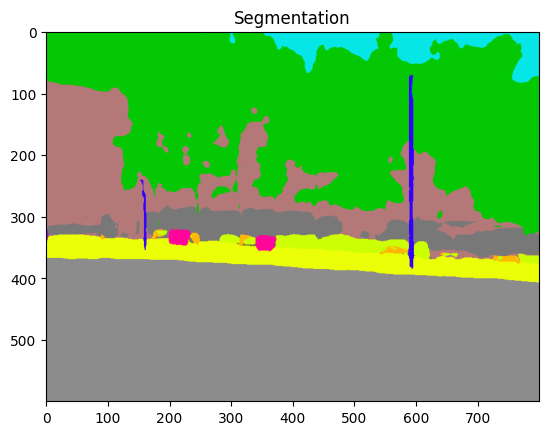

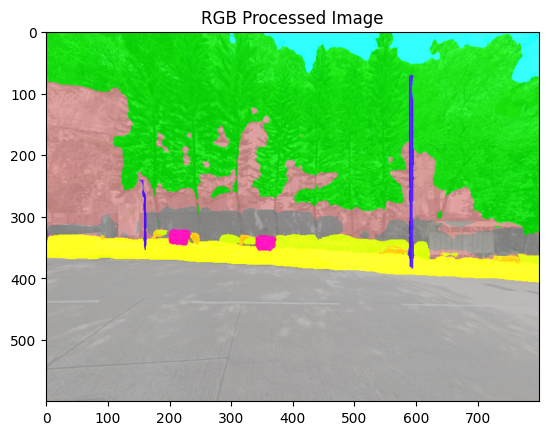

/tmp/ipykernel_754/51785540.py:80: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, current_df], ignore_index=True)


Processed 2/99 images, 41_114.206538_22.34513935.jpg
Processed 2/99 images, 41_114.206538_22.34513935.jpg


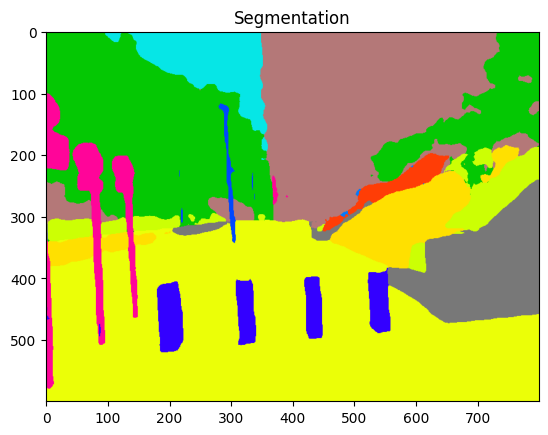

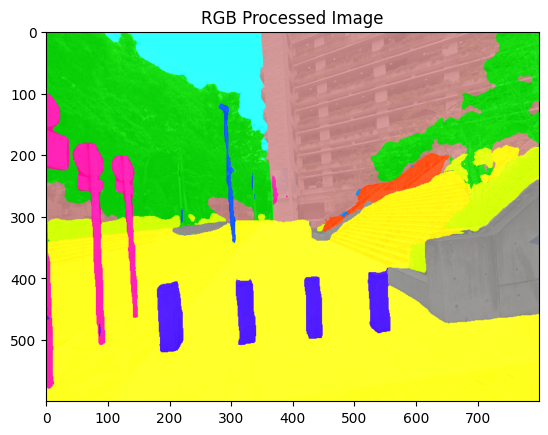

Processed 3/99 images, 99_114.2038118_22.34648376.jpg
Processed 3/99 images, 99_114.2038118_22.34648376.jpg


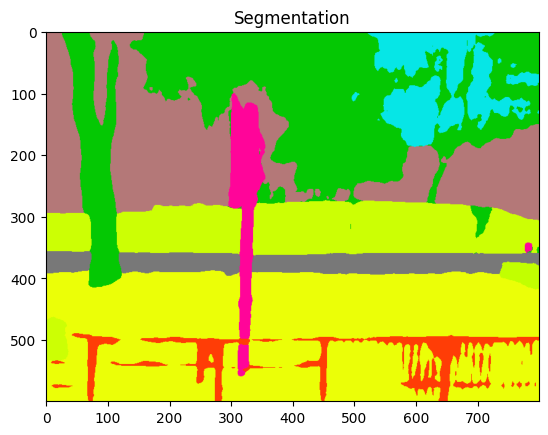

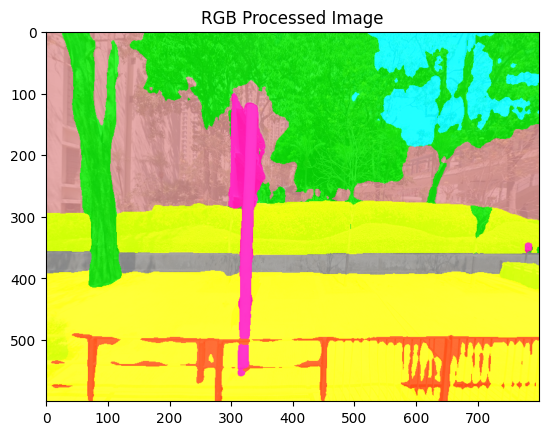

Processed 4/99 images, 15_114.2069954_22.34482391.jpg
Processed 4/99 images, 15_114.2069954_22.34482391.jpg


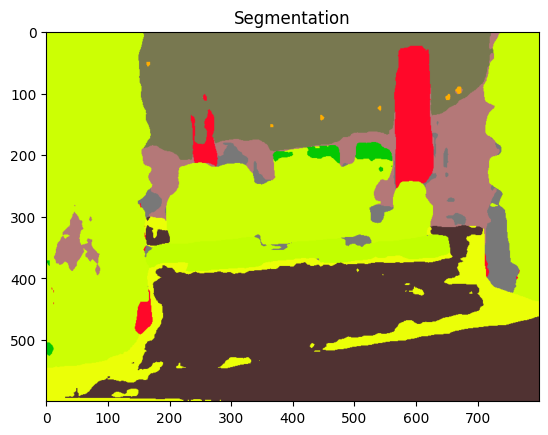

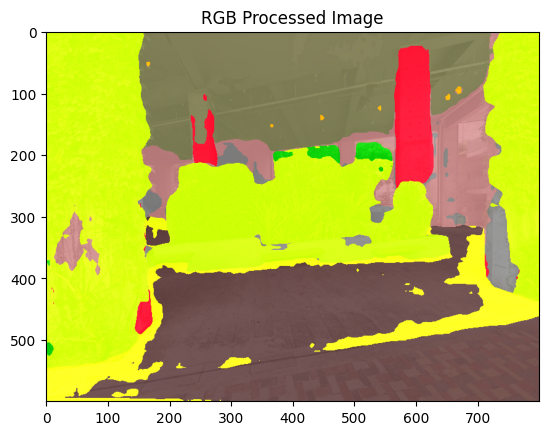

Processed 5/99 images, 108_114.2018056_22.3460782.jpg
Processed 5/99 images, 108_114.2018056_22.3460782.jpg


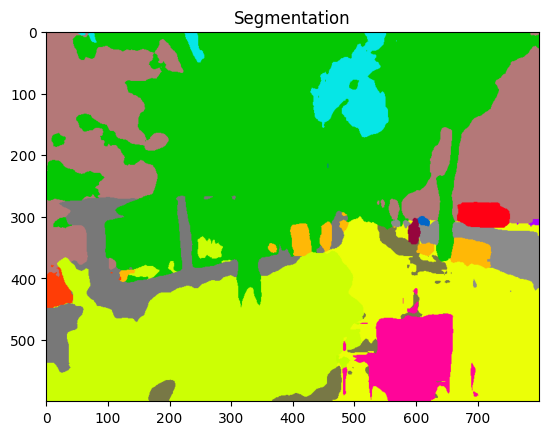

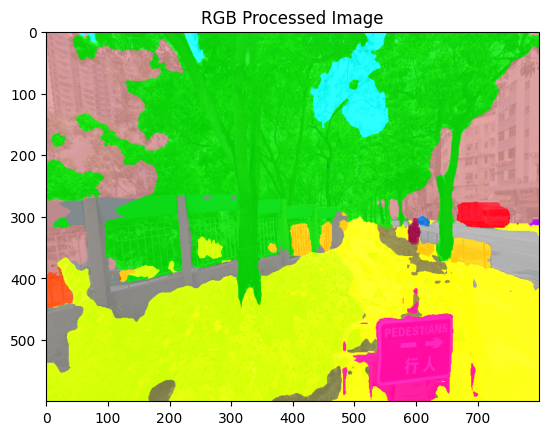

Processed 6/99 images, 42_114.2068726_22.34481221.jpg
Processed 6/99 images, 42_114.2068726_22.34481221.jpg


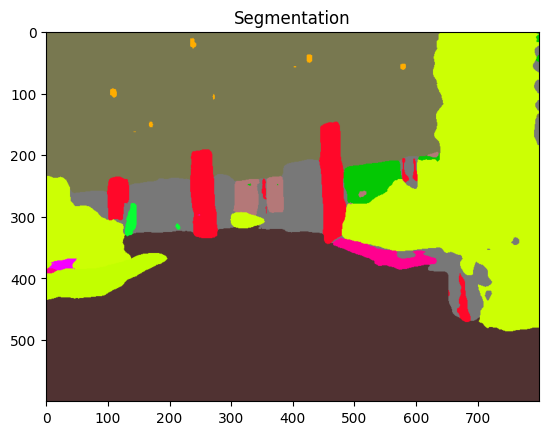

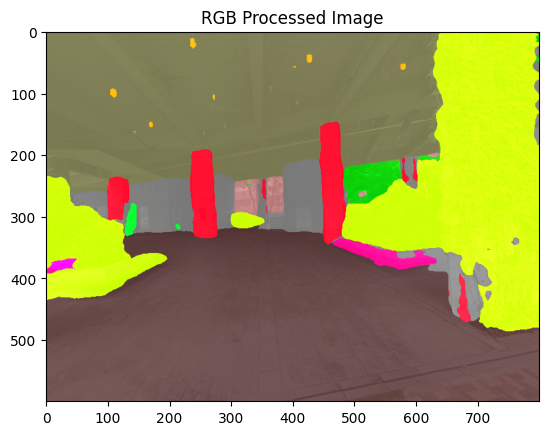

Processed 7/99 images, 88_114.2041893_22.3461107.jpg
Processed 7/99 images, 88_114.2041893_22.3461107.jpg


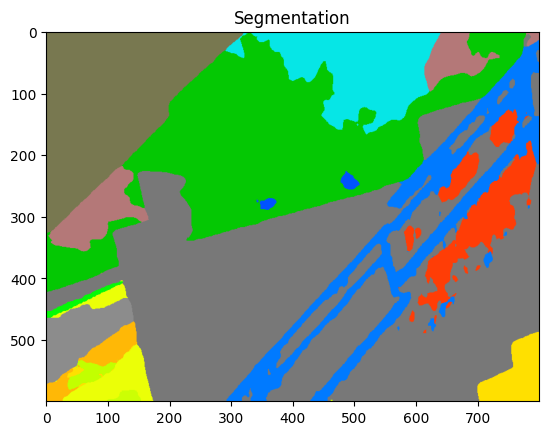

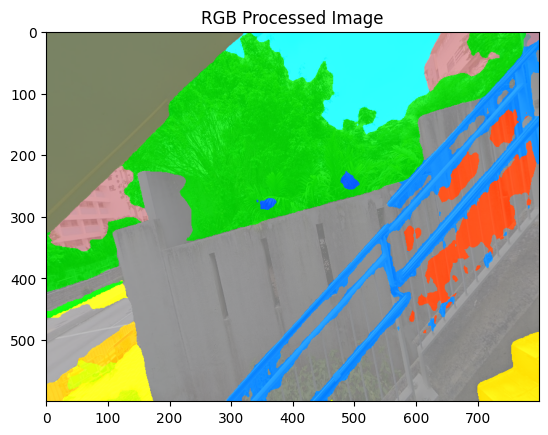

Processed 8/99 images, 113_114.2026606_22.34500328.jpg
Processed 8/99 images, 113_114.2026606_22.34500328.jpg


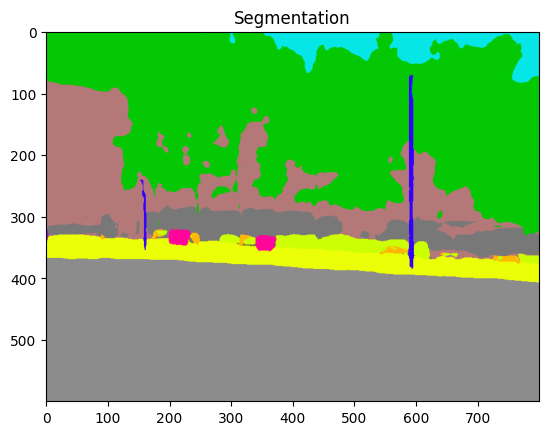

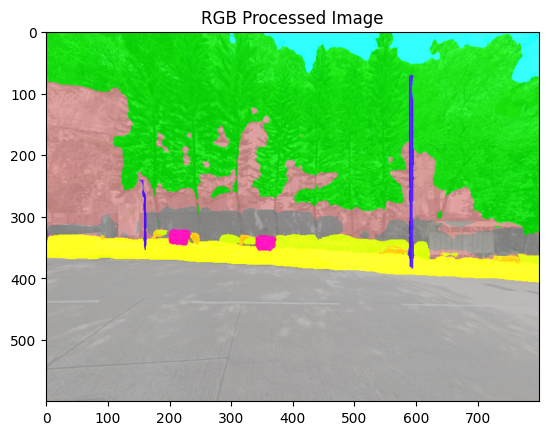

Processed 9/99 images, 75_114.2033194_22.34633492.jpg
Processed 9/99 images, 75_114.2033194_22.34633492.jpg


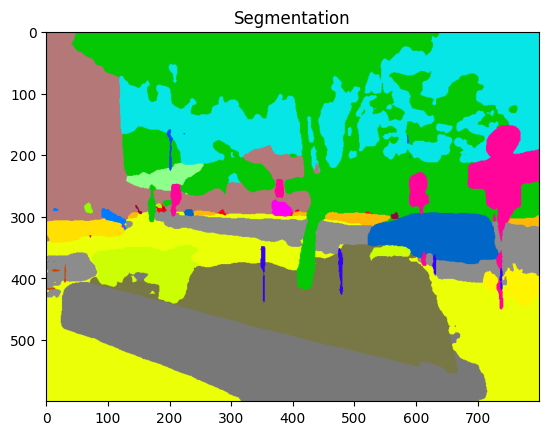

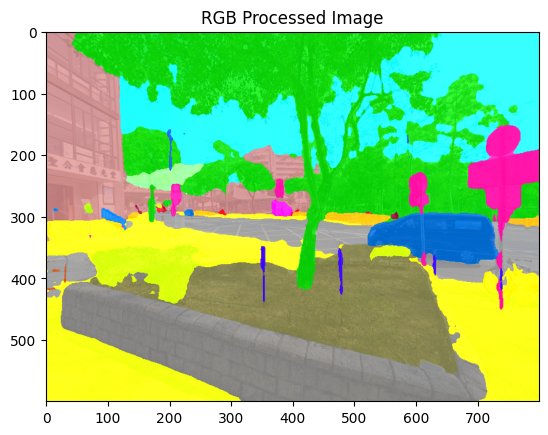

Processed 10/99 images, 44_114.2061605_22.3458059.jpg
Processed 10/99 images, 44_114.2061605_22.3458059.jpg


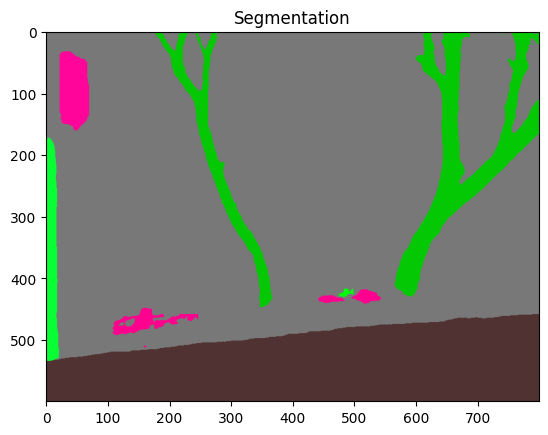

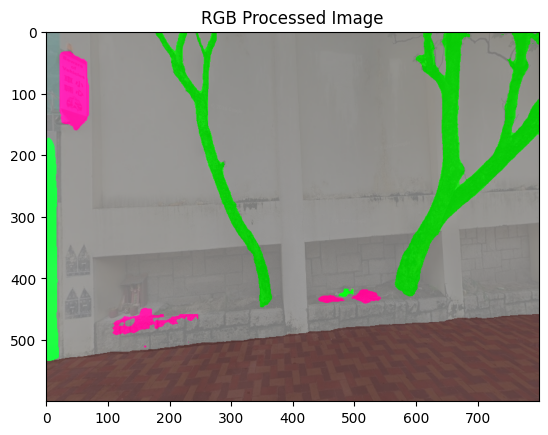

Processed 11/99 images, 12_114.2060109_22.34582086.jpg
Processed 11/99 images, 12_114.2060109_22.34582086.jpg


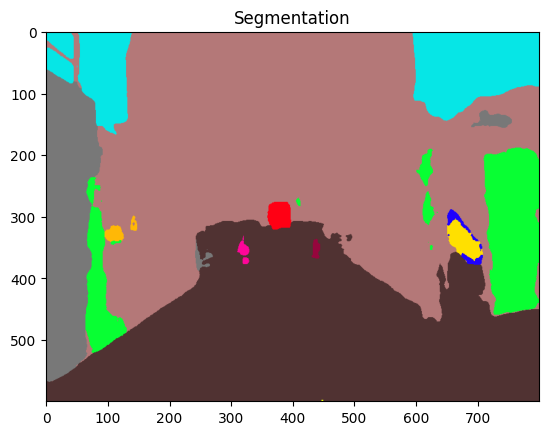

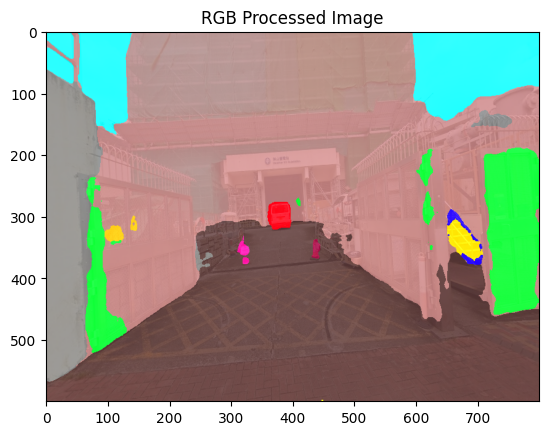

Processed 12/99 images, 46_114.2068023_22.34514831.jpg
Processed 12/99 images, 46_114.2068023_22.34514831.jpg


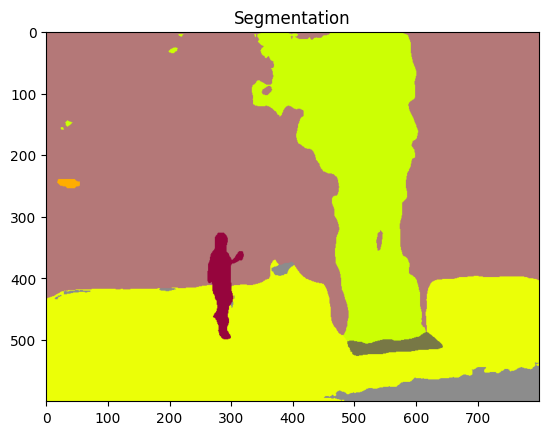

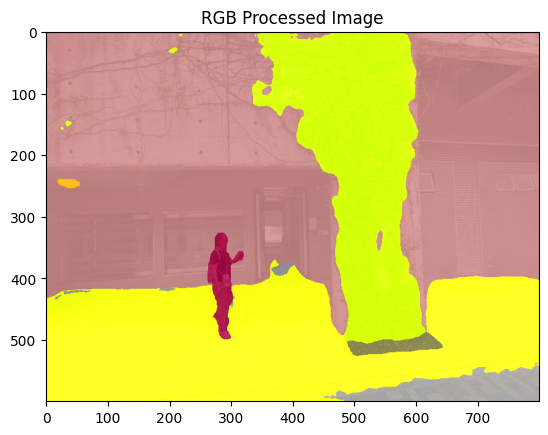

Processed 13/99 images, 55_114.2062833_22.34351829.jpg
Processed 13/99 images, 55_114.2062833_22.34351829.jpg


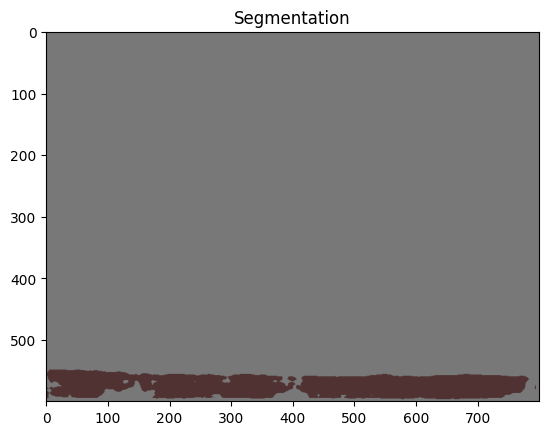

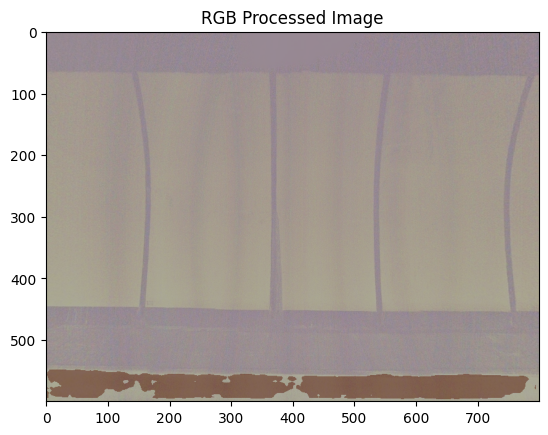

Processed 14/99 images, 35_114.2027281_22.3441276.jpg
Processed 14/99 images, 35_114.2027281_22.3441276.jpg


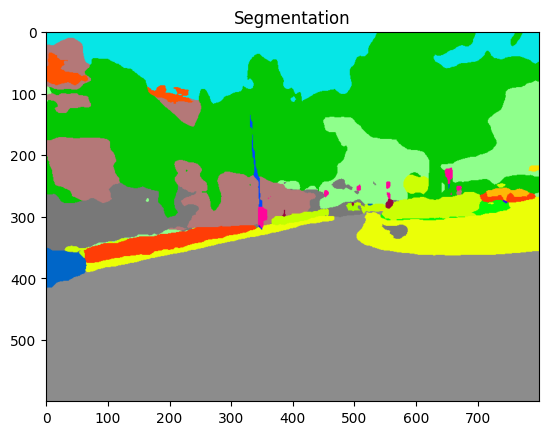

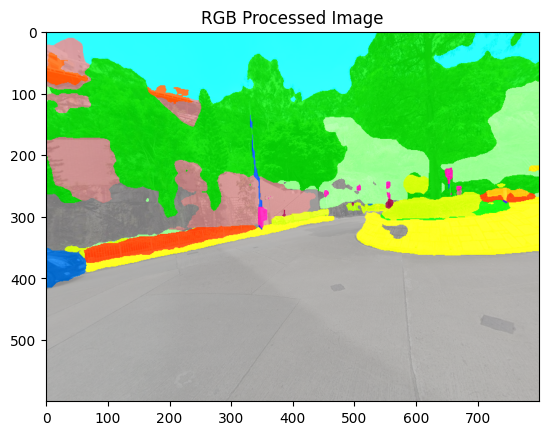

Processed 15/99 images, 81_114.201654_22.3462771.jpg
Processed 15/99 images, 81_114.201654_22.3462771.jpg


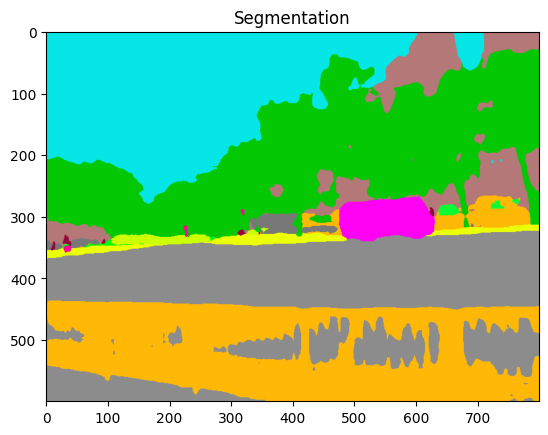

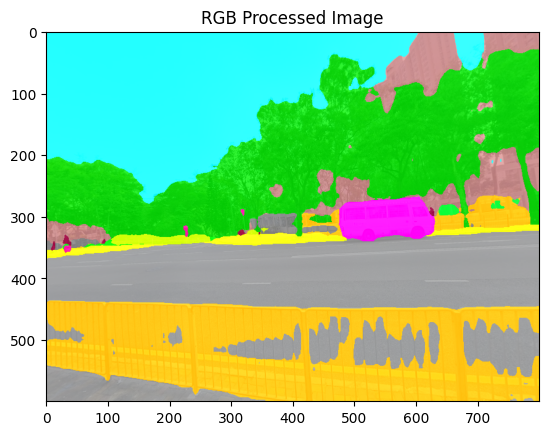

Processed 16/99 images, 53_114.2060135_22.34433776.jpg
Processed 16/99 images, 53_114.2060135_22.34433776.jpg


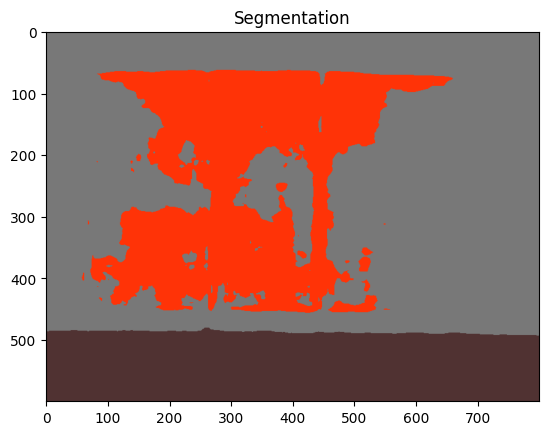

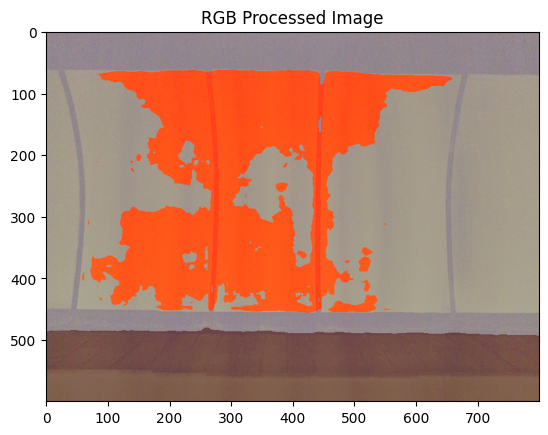

Processed 17/99 images, 60_114.2051083_22.34284785.jpg
Processed 17/99 images, 60_114.2051083_22.34284785.jpg


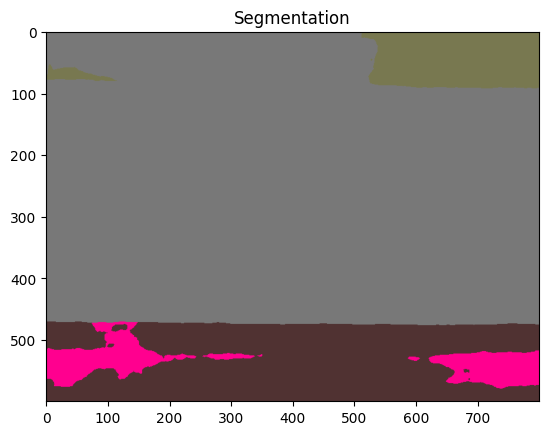

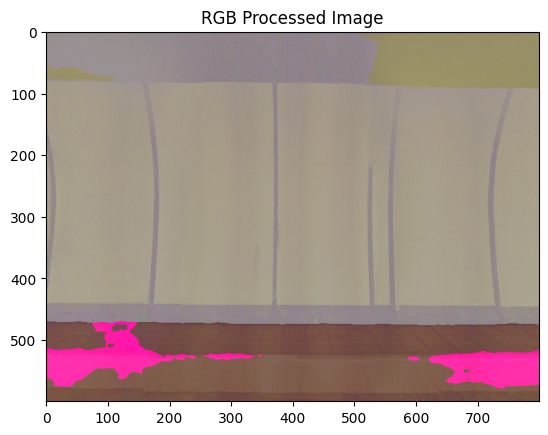

Processed 18/99 images, 90_114.20271_22.3450126.jpg
Processed 18/99 images, 90_114.20271_22.3450126.jpg


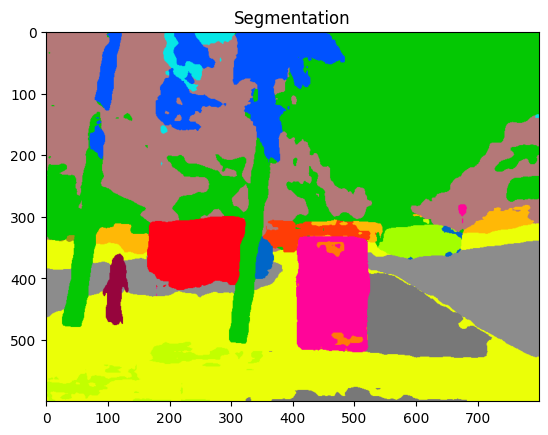

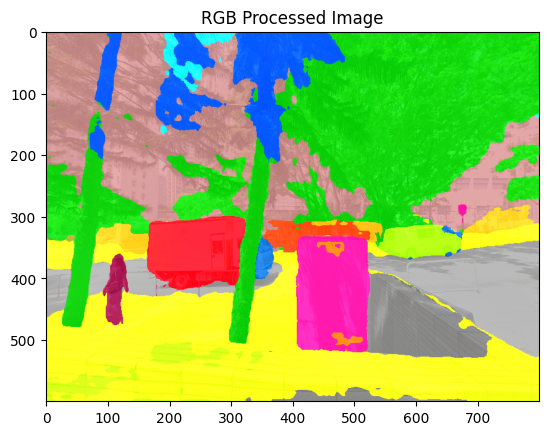

Processed 19/99 images, 91_114.2029608_22.34467163.jpg
Processed 19/99 images, 91_114.2029608_22.34467163.jpg


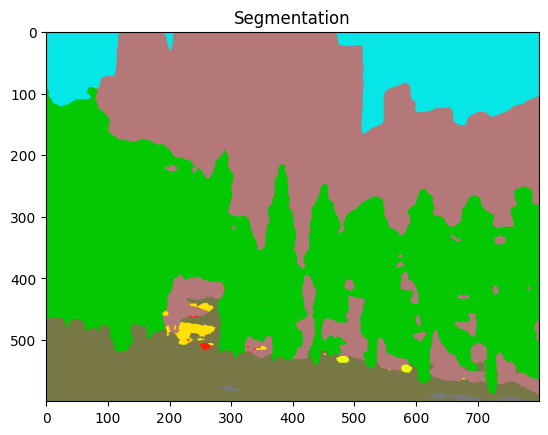

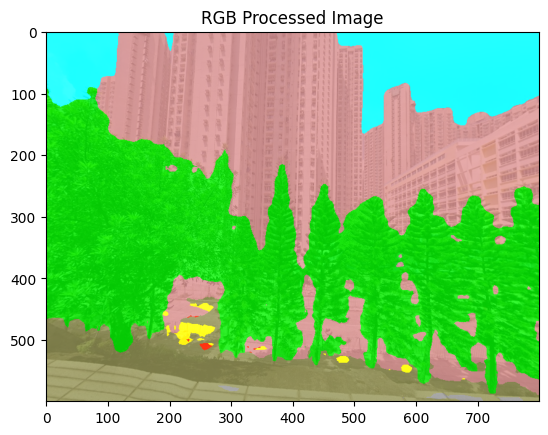

Processed 20/99 images, 72_114.2019041_22.3460892.jpg
Processed 20/99 images, 72_114.2019041_22.3460892.jpg


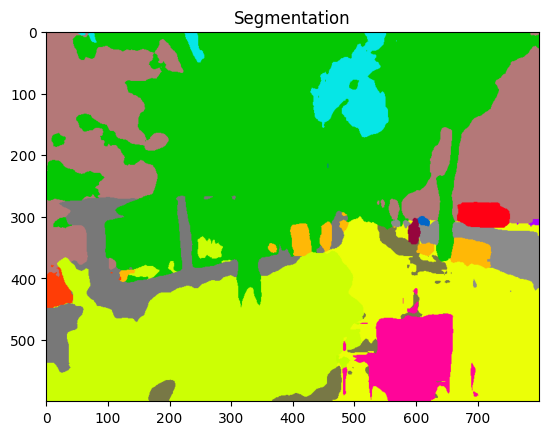

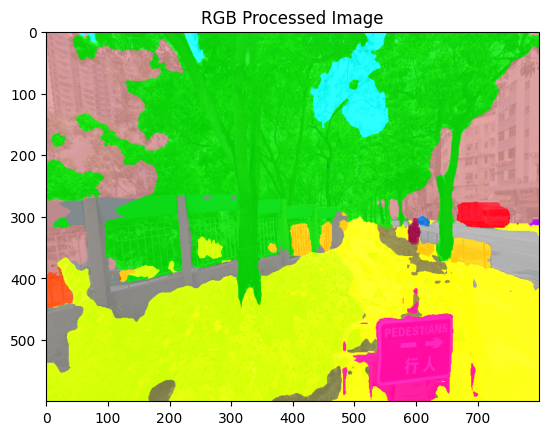

Processed 21/99 images, 16_114.2024391_22.34298986.jpg
Processed 21/99 images, 16_114.2024391_22.34298986.jpg


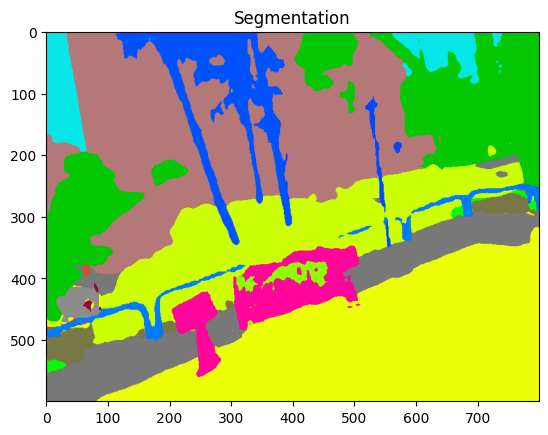

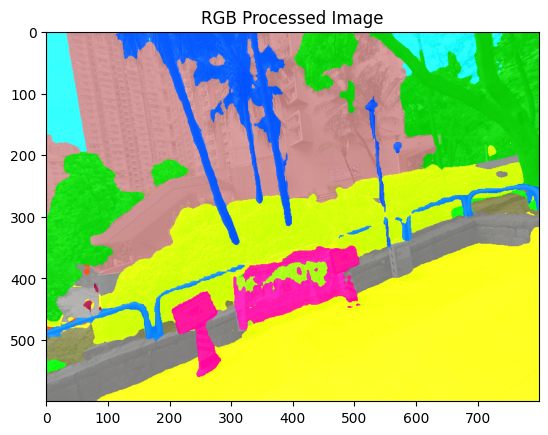

Processed 22/99 images, 89_114.2042718_22.3461083.jpg
Processed 22/99 images, 89_114.2042718_22.3461083.jpg


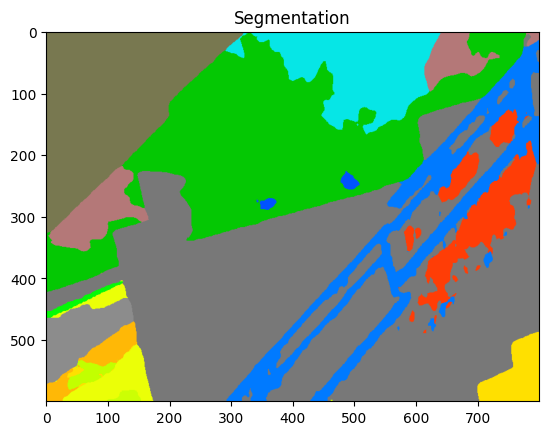

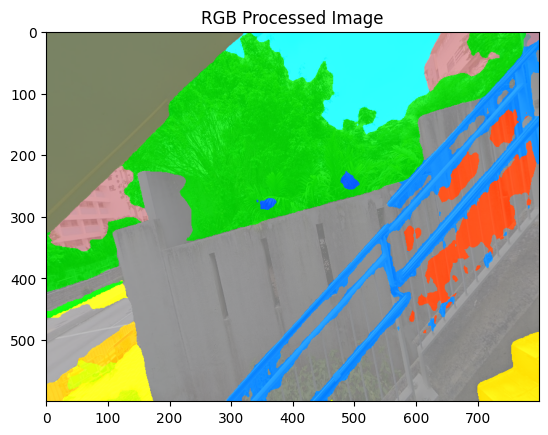

Processed 23/99 images, 8_114.2021961_22.34541239.jpg
Processed 23/99 images, 8_114.2021961_22.34541239.jpg


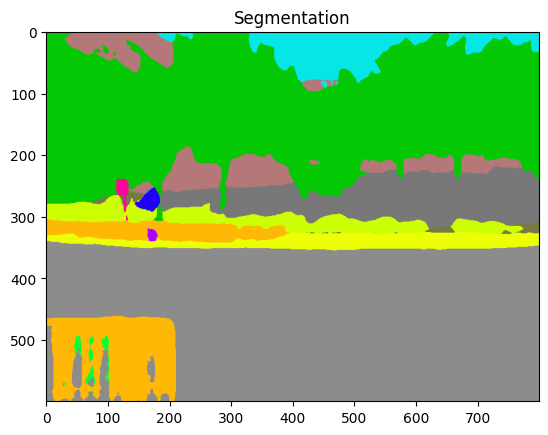

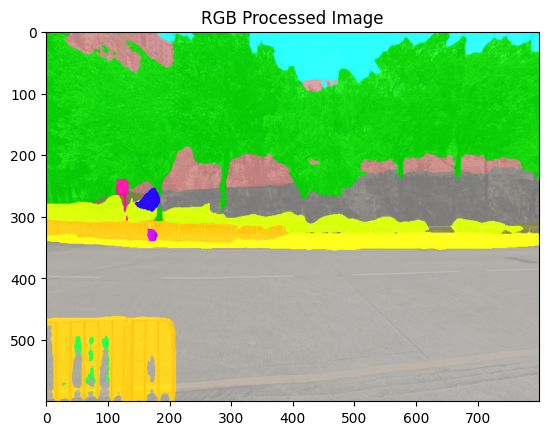

Processed 24/99 images, 66_114.2058465_22.34497151.jpg
Processed 24/99 images, 66_114.2058465_22.34497151.jpg


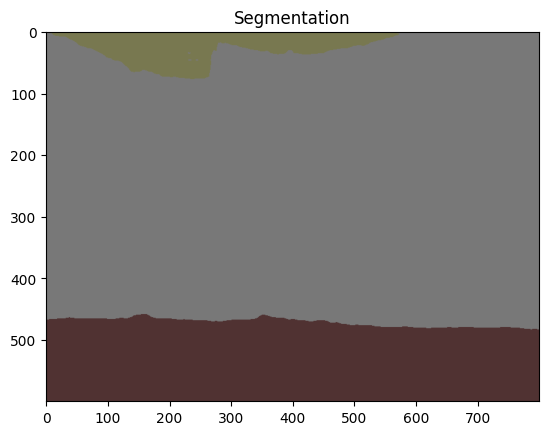

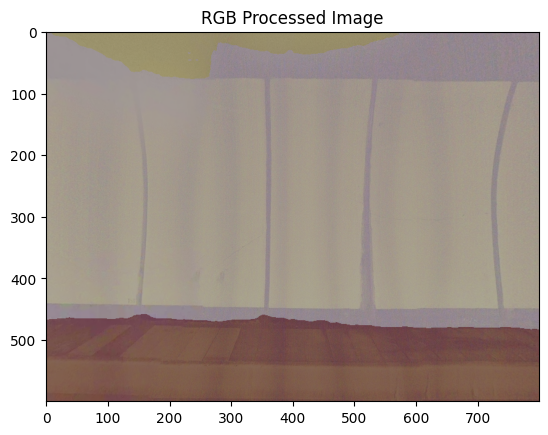

Processed 25/99 images, 52_114.2055864_22.34423365.jpg
Processed 25/99 images, 52_114.2055864_22.34423365.jpg


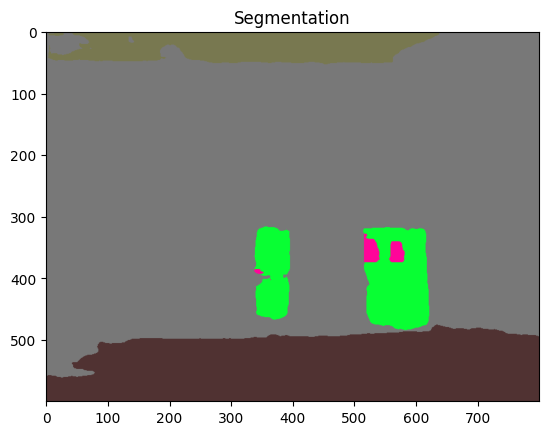

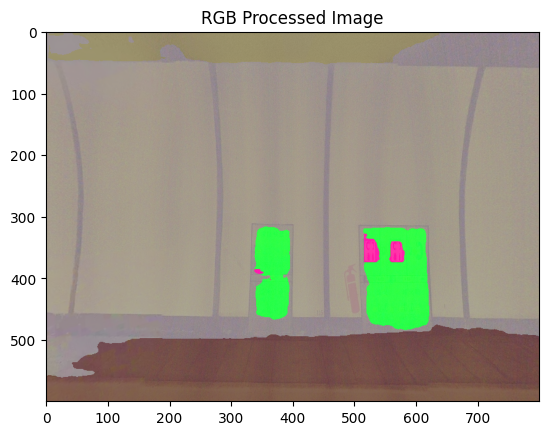

Processed 26/99 images, 34_114.2034459_22.34586599.jpg
Processed 26/99 images, 34_114.2034459_22.34586599.jpg


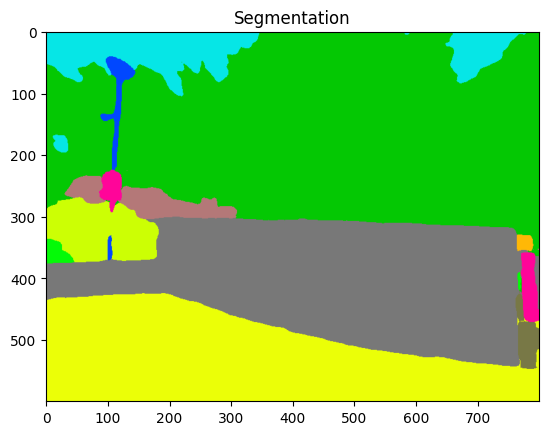

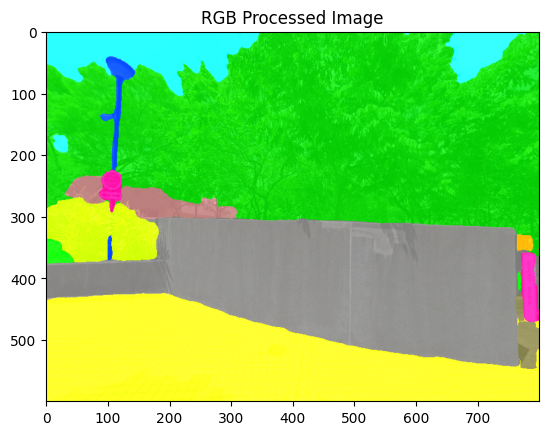

Processed 27/99 images, 63_114.2060066_22.34307383.jpg
Processed 27/99 images, 63_114.2060066_22.34307383.jpg


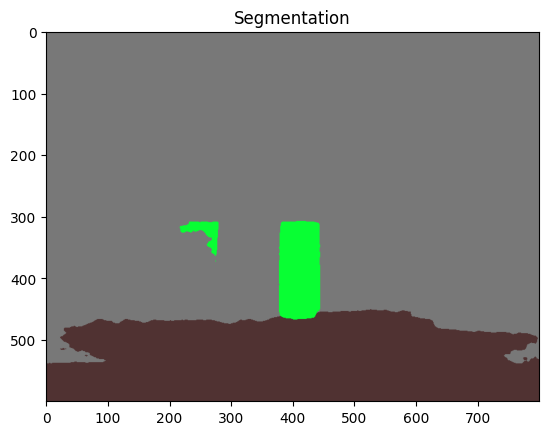

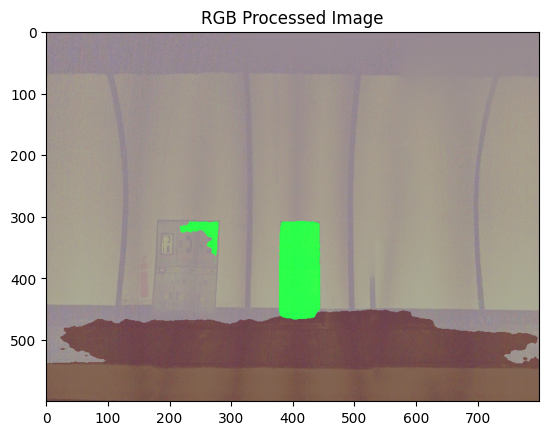

Processed 28/99 images, 37_114.2035459_22.3453913.jpg
Processed 28/99 images, 37_114.2035459_22.3453913.jpg


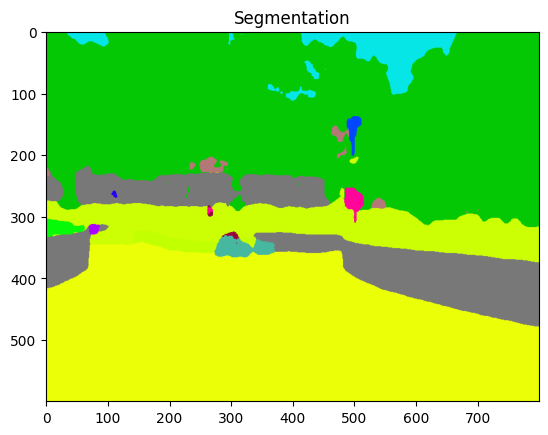

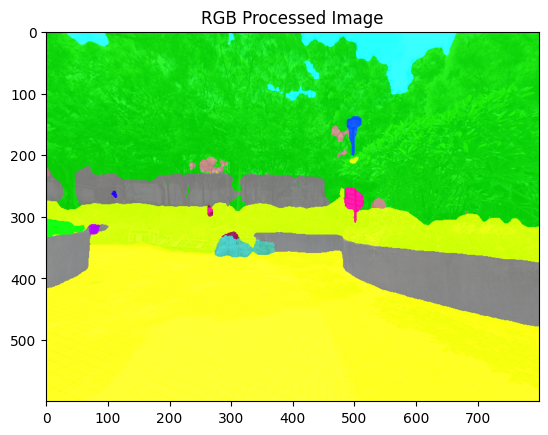

Processed 29/99 images, 40_114.2062035_22.34546649.jpg
Processed 29/99 images, 40_114.2062035_22.34546649.jpg


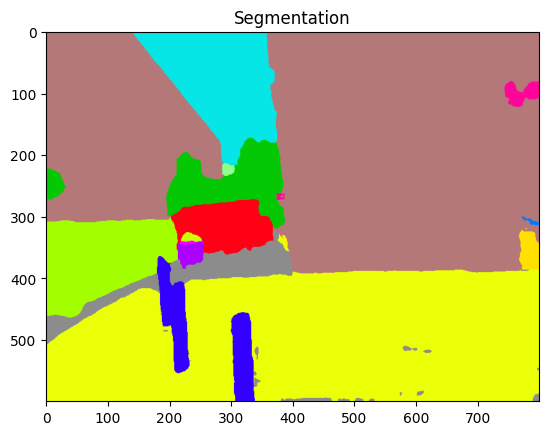

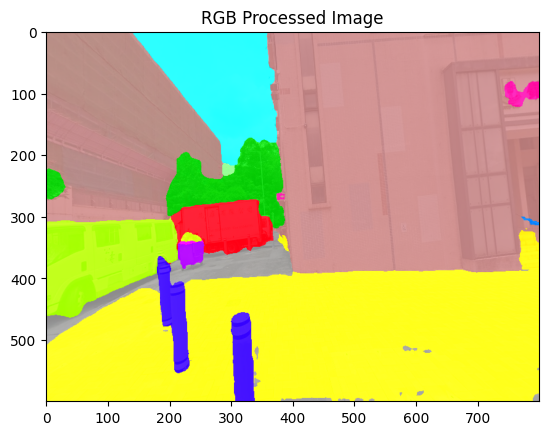

Processed 30/99 images, 78_114.2030892_22.3463022.jpg
Processed 30/99 images, 78_114.2030892_22.3463022.jpg


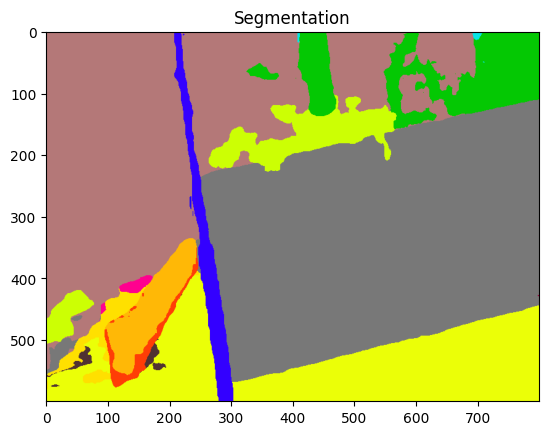

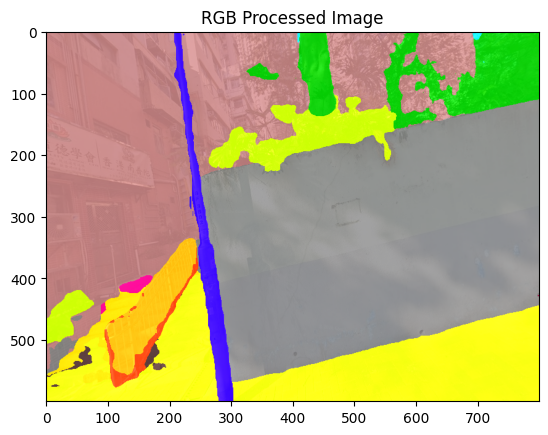

Processed 31/99 images, 62_114.2055283_22.34299664.jpg
Processed 31/99 images, 62_114.2055283_22.34299664.jpg


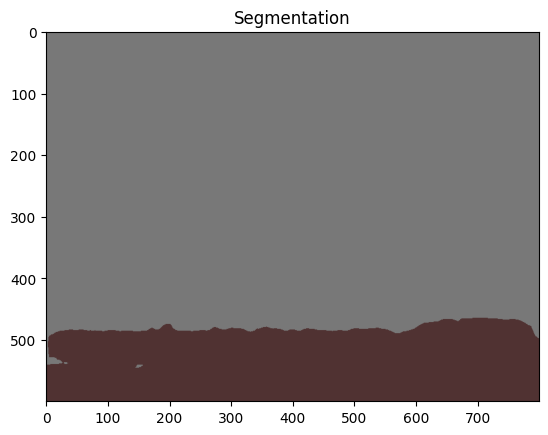

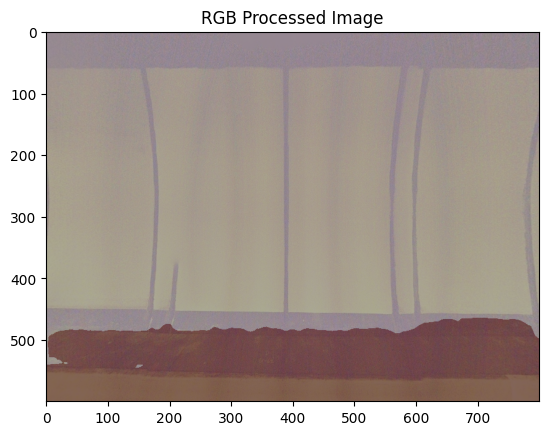

Processed 32/99 images, 94_114.2028803_22.3464461.jpg
Processed 32/99 images, 94_114.2028803_22.3464461.jpg


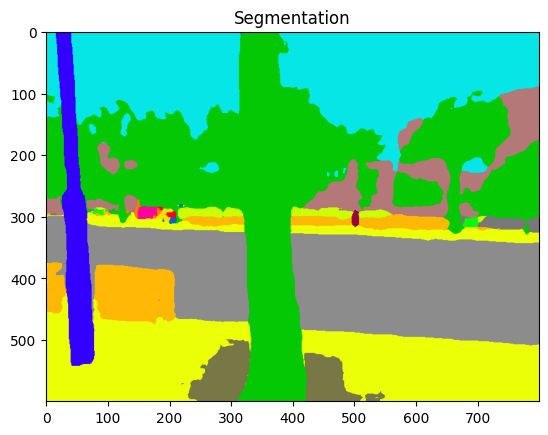

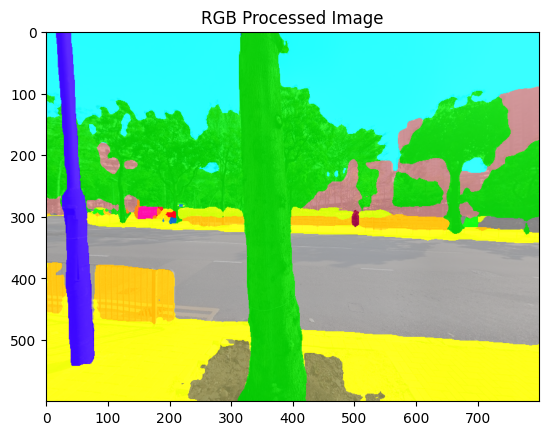

Processed 33/99 images, 39_114.2058689_22.34579363.jpg
Processed 33/99 images, 39_114.2058689_22.34579363.jpg


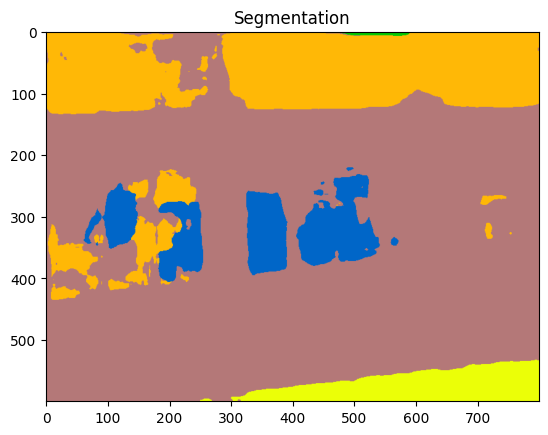

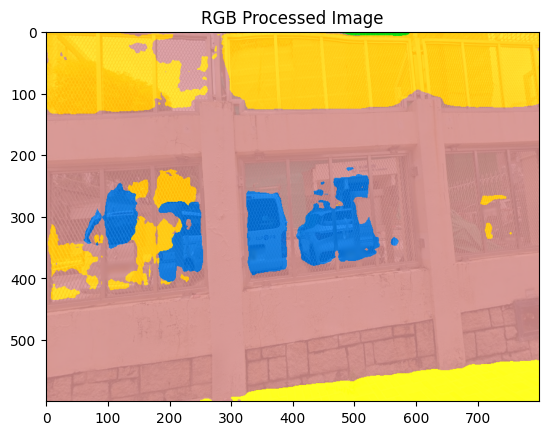

Processed 34/99 images, 65_114.2061311_22.345333.jpg
Processed 34/99 images, 65_114.2061311_22.345333.jpg


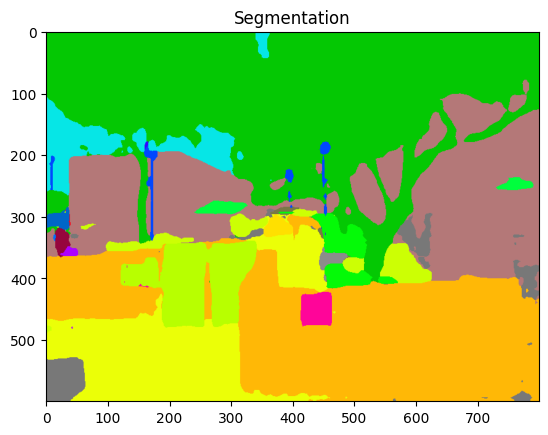

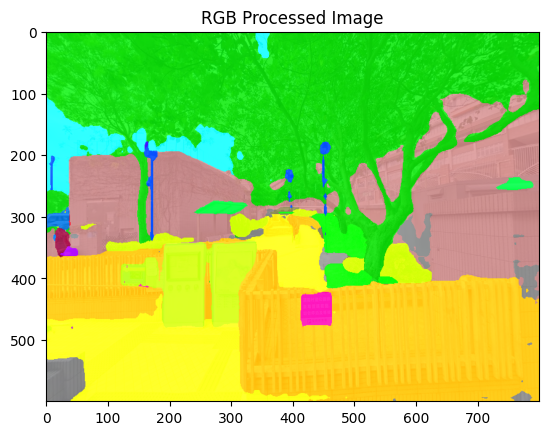

Processed 35/99 images, 105_114.2026674_22.34451602.jpg
Processed 35/99 images, 105_114.2026674_22.34451602.jpg


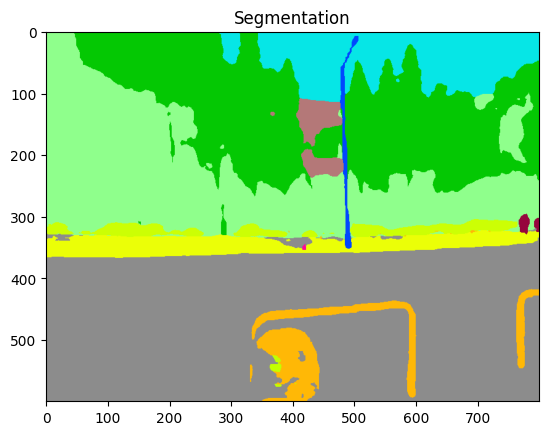

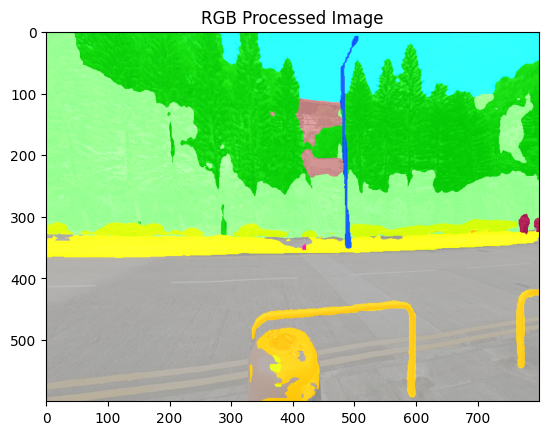

Processed 36/99 images, 14_114.2066731_22.34516149.jpg
Processed 36/99 images, 14_114.2066731_22.34516149.jpg


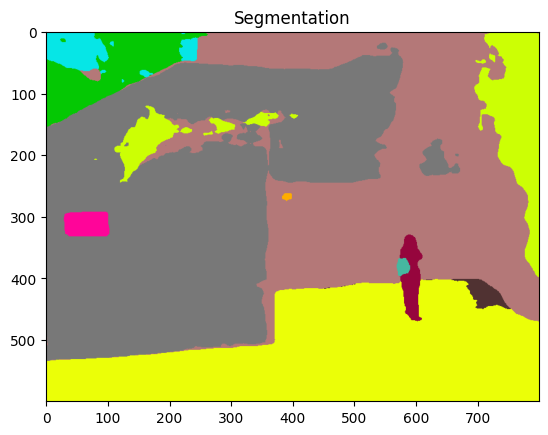

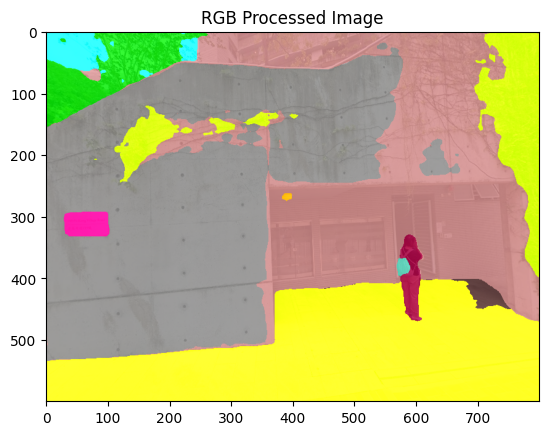

Processed 37/99 images, 70_114.2023158_22.34455755.jpg
Processed 37/99 images, 70_114.2023158_22.34455755.jpg


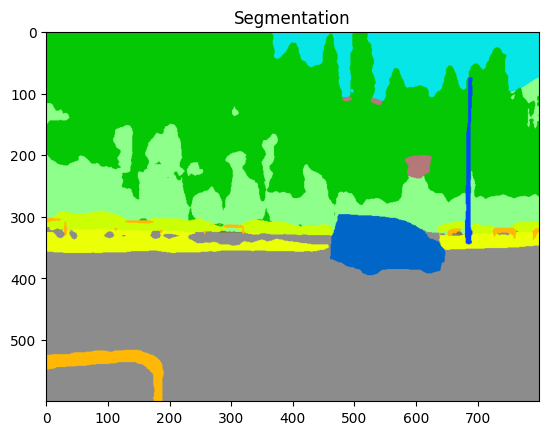

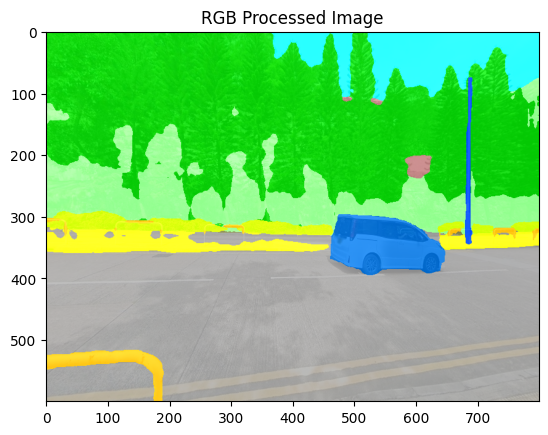

Processed 38/99 images, 10_114.2026833_22.34468319.jpg
Processed 38/99 images, 10_114.2026833_22.34468319.jpg


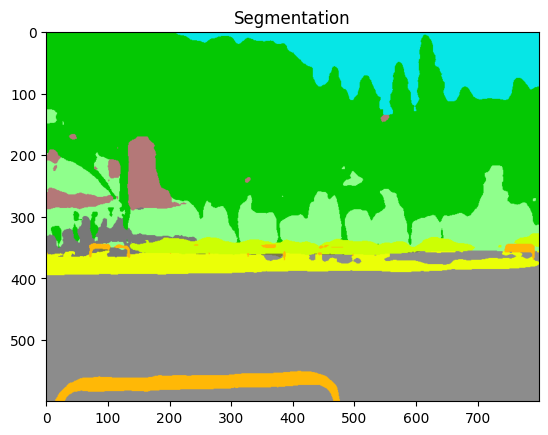

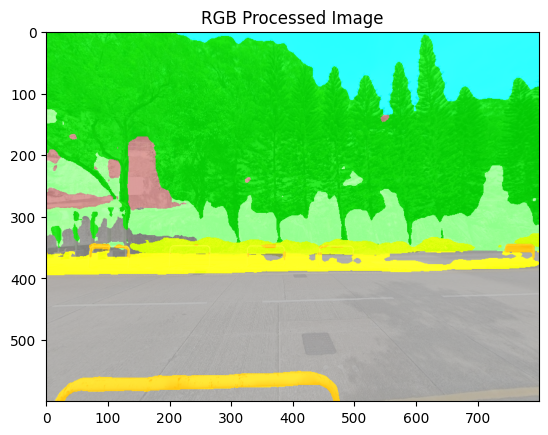

Processed 39/99 images, 23_114.2032839_22.3464107.jpg
Processed 39/99 images, 23_114.2032839_22.3464107.jpg


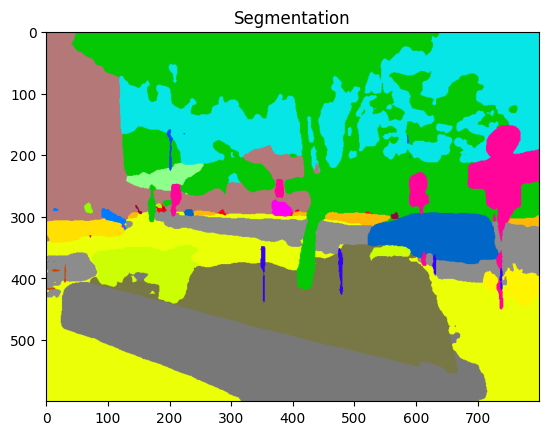

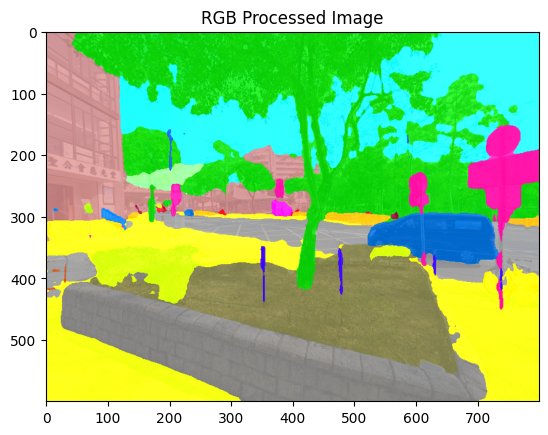

Processed 40/99 images, 96_114.2032763_22.3465958.jpg
Processed 40/99 images, 96_114.2032763_22.3465958.jpg


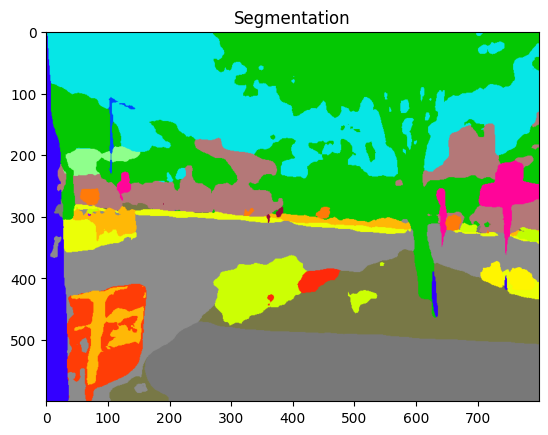

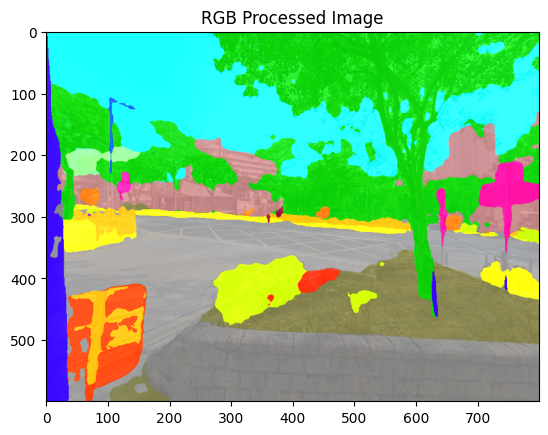

Processed 41/99 images, 19_114.2015217_22.34616744.jpg
Processed 41/99 images, 19_114.2015217_22.34616744.jpg


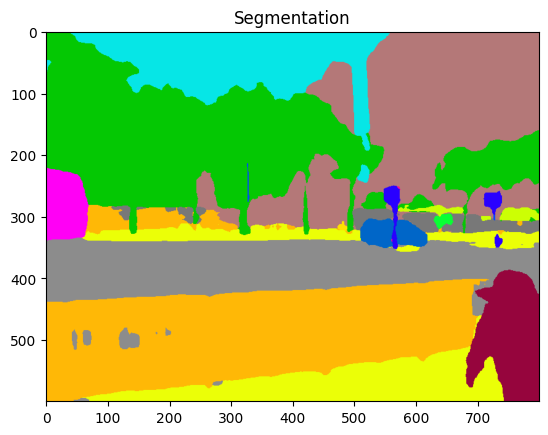

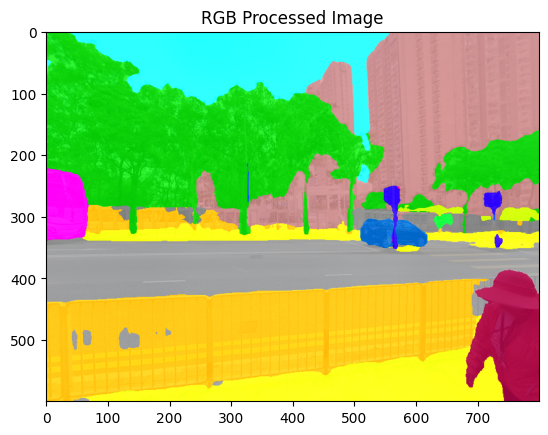

Processed 42/99 images, 73_114.2023592_22.34620183.jpg
Processed 42/99 images, 73_114.2023592_22.34620183.jpg


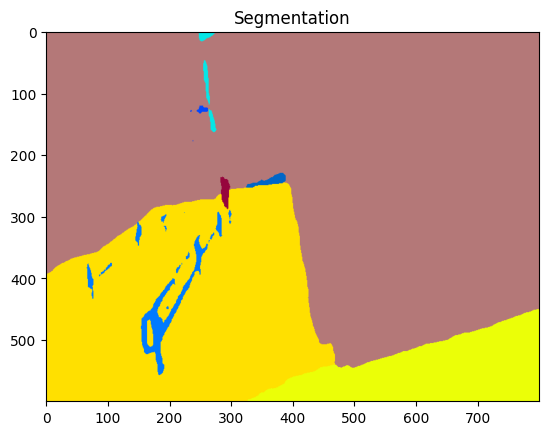

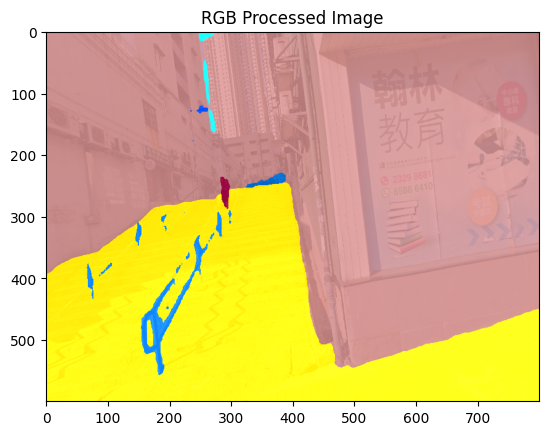

Processed 43/99 images, 111_114.2020216_22.34565305.jpg
Processed 43/99 images, 111_114.2020216_22.34565305.jpg


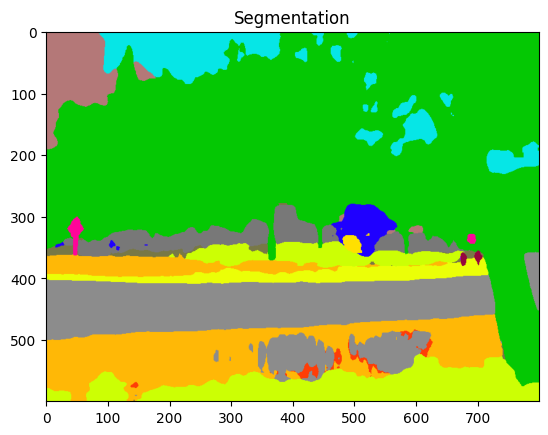

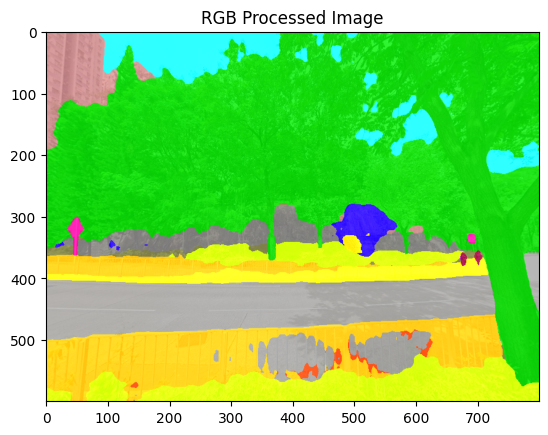

Processed 44/99 images, 102_114.2027716_22.34456087.jpg
Processed 44/99 images, 102_114.2027716_22.34456087.jpg


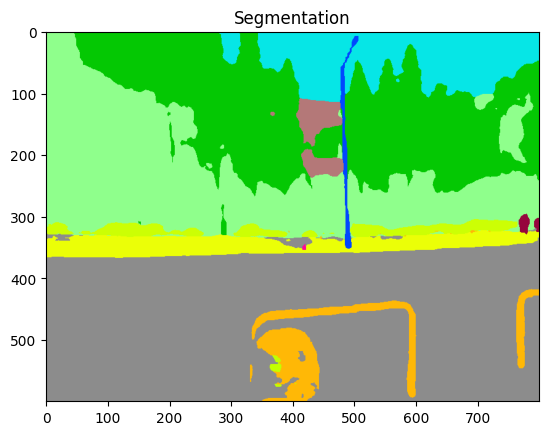

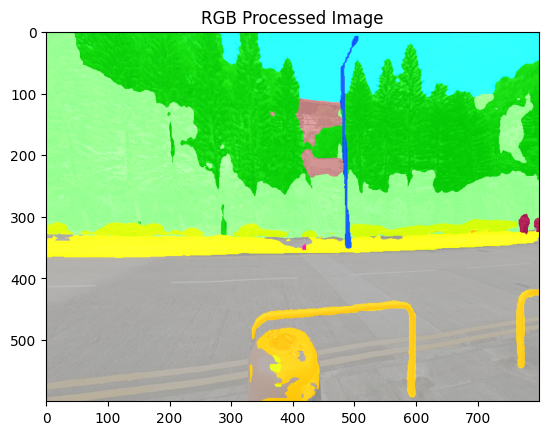

Processed 45/99 images, 38_114.2036205_22.3455656.jpg
Processed 45/99 images, 38_114.2036205_22.3455656.jpg


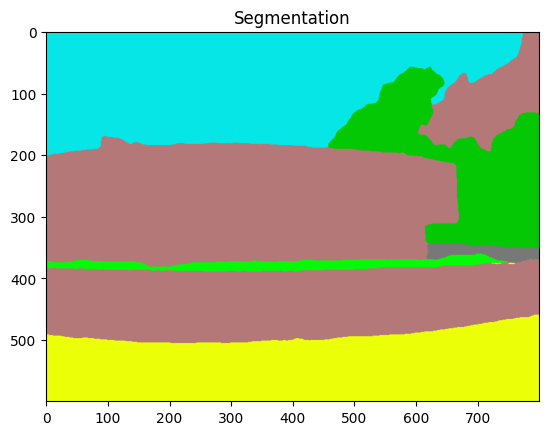

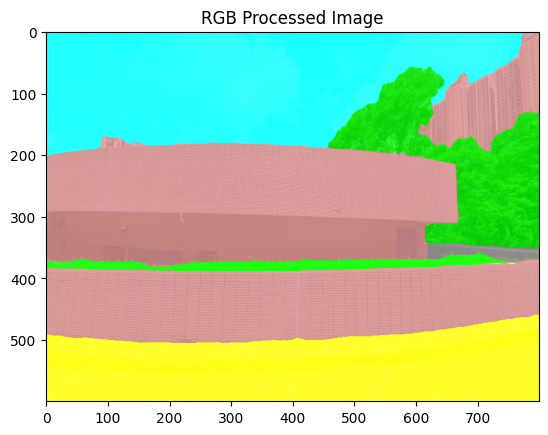

Processed 46/99 images, 17_114.2027249_22.34329875.jpg
Processed 46/99 images, 17_114.2027249_22.34329875.jpg


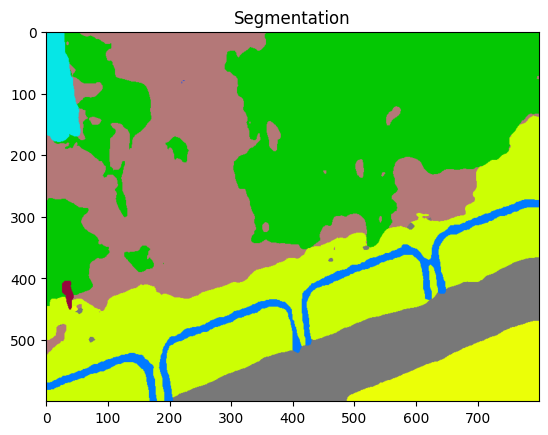

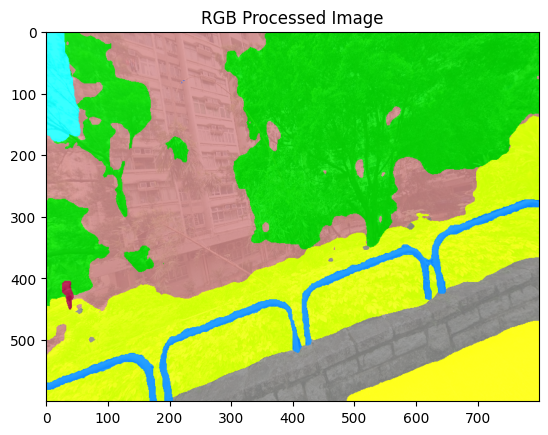

Processed 47/99 images, 47_114.2048444_22.3429361.jpg
Processed 47/99 images, 47_114.2048444_22.3429361.jpg


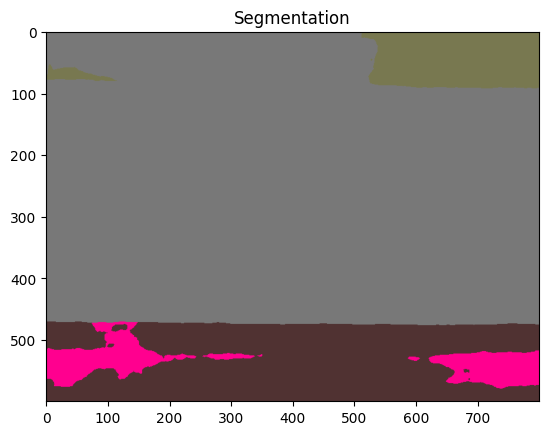

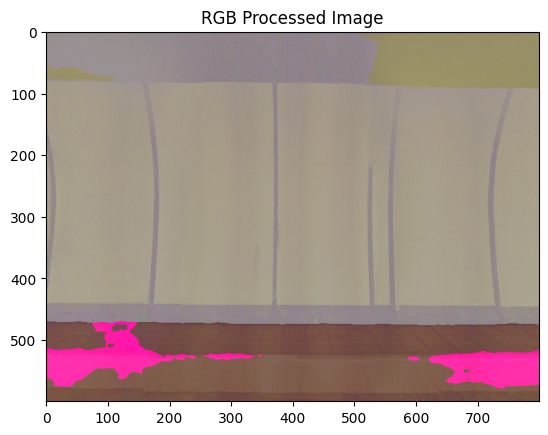

Processed 48/99 images, 79_114.2061491_22.34581008.jpg
Processed 48/99 images, 79_114.2061491_22.34581008.jpg


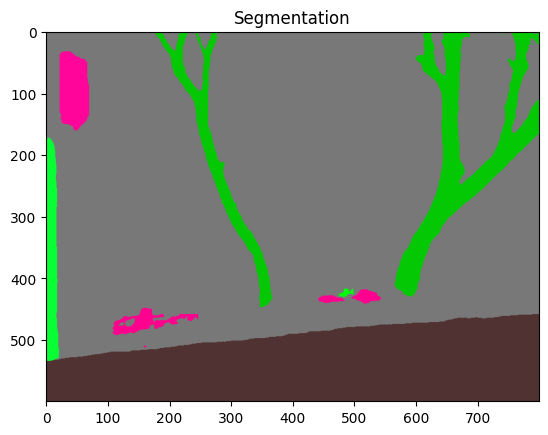

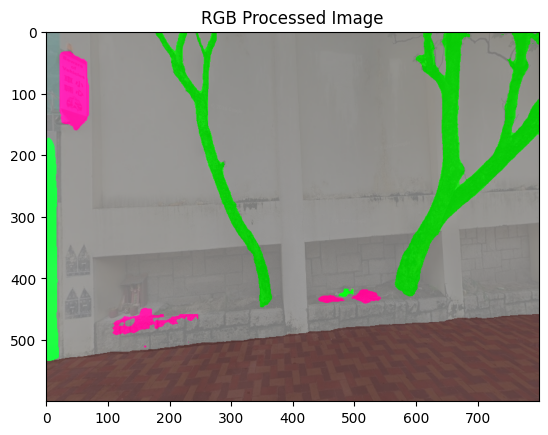

Processed 49/99 images, 54_114.2062044_22.34396381.jpg
Processed 49/99 images, 54_114.2062044_22.34396381.jpg


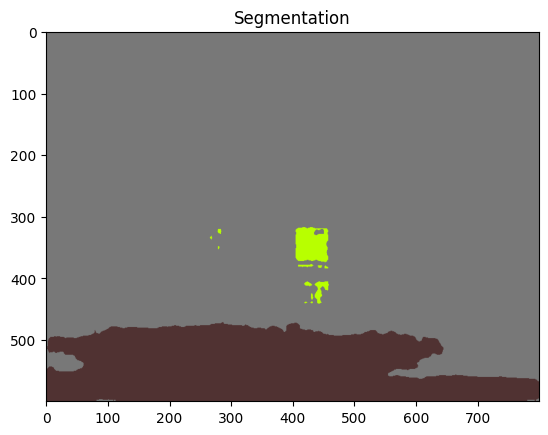

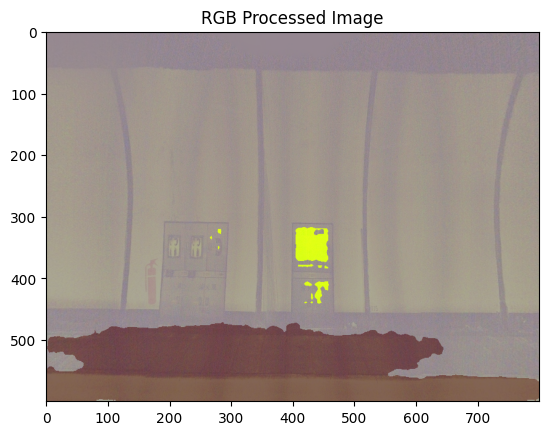

Processed 50/99 images, 20_114.2018435_22.3462117.jpg
Processed 50/99 images, 20_114.2018435_22.3462117.jpg


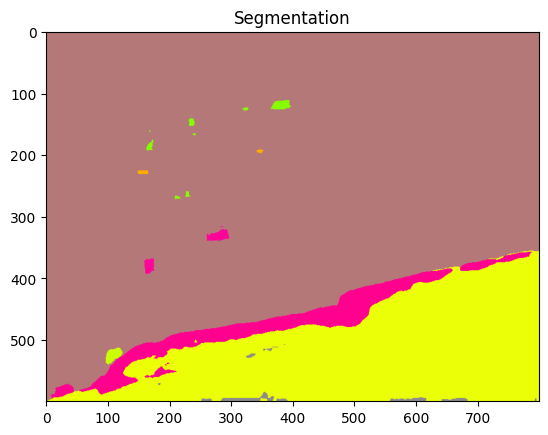

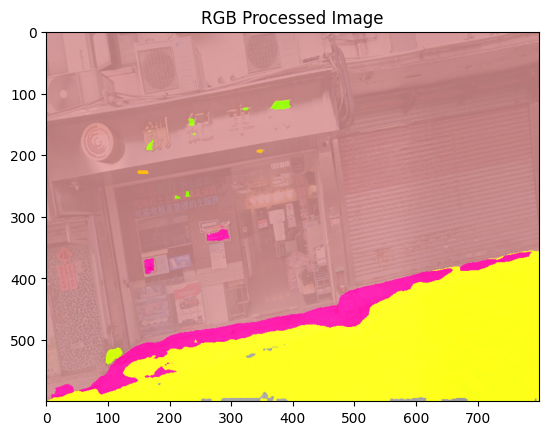

Processed 51/99 images, 59_114.2055347_22.34263562.jpg
Processed 51/99 images, 59_114.2055347_22.34263562.jpg


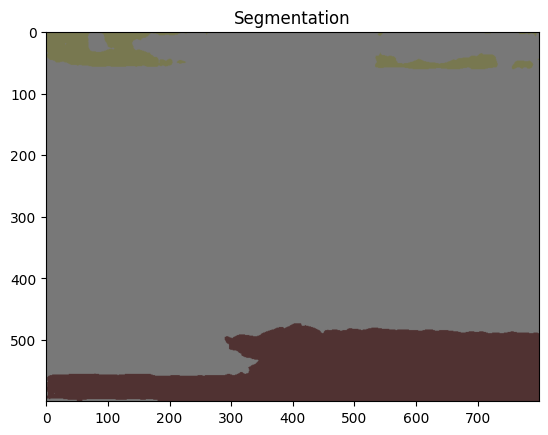

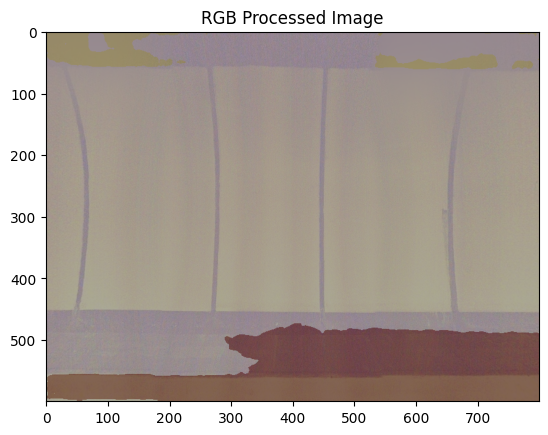

Processed 52/99 images, 103_114.202881_22.34412096.jpg
Processed 52/99 images, 103_114.202881_22.34412096.jpg


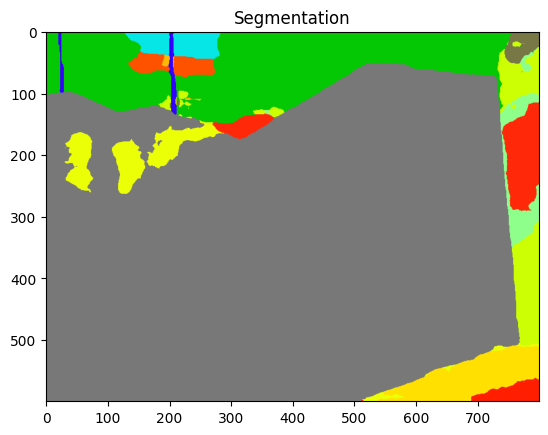

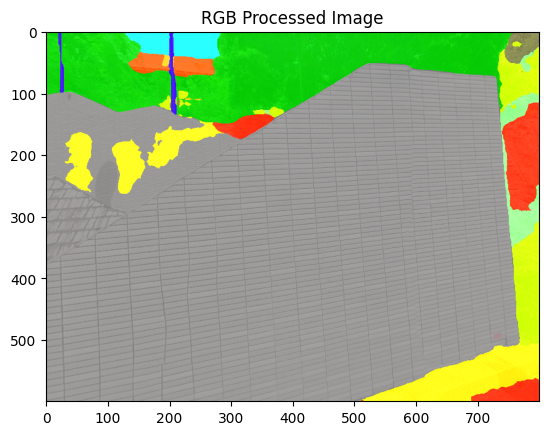

Processed 53/99 images, 43_114.2041124_22.34633564.jpg
Processed 53/99 images, 43_114.2041124_22.34633564.jpg


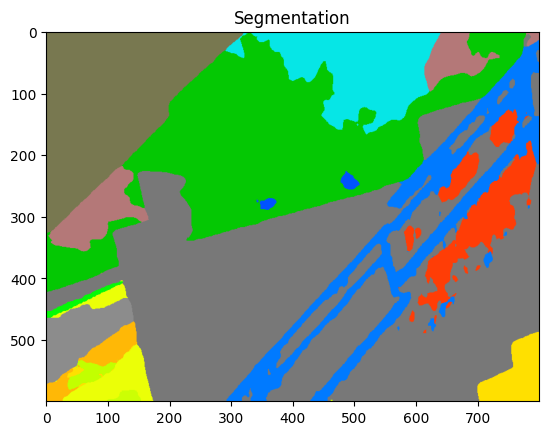

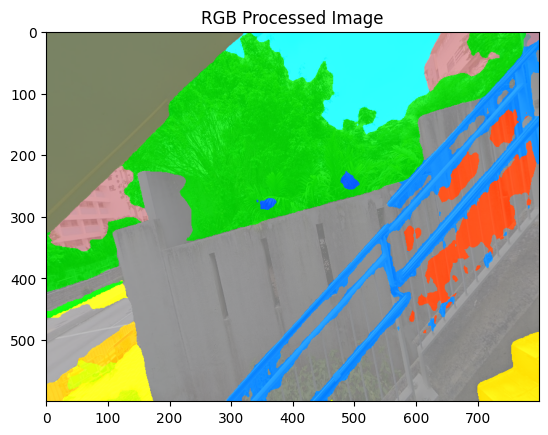

Processed 54/99 images, 71_114.2018236_22.3460803.jpg
Processed 54/99 images, 71_114.2018236_22.3460803.jpg


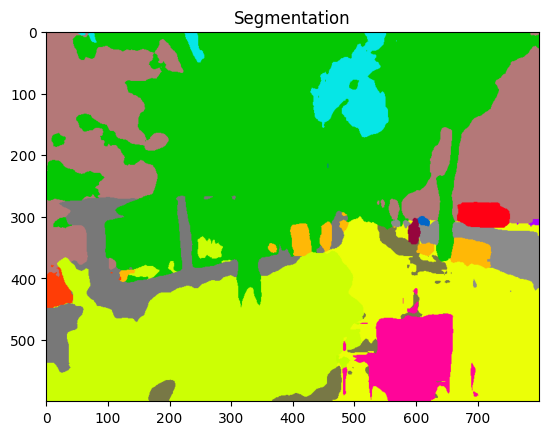

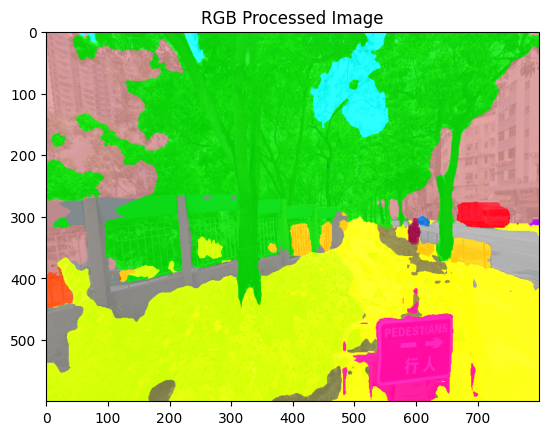

Processed 55/99 images, 4_114.2019875_22.3464264.jpg
Processed 55/99 images, 4_114.2019875_22.3464264.jpg


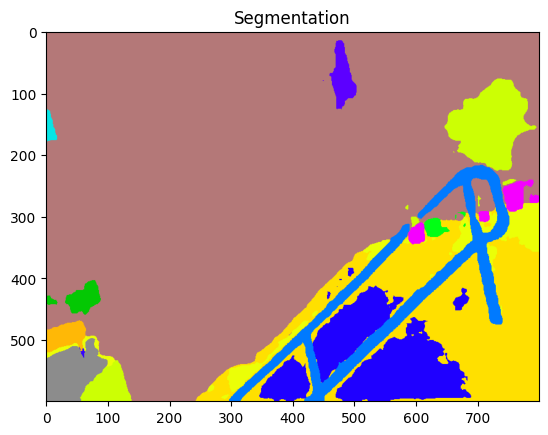

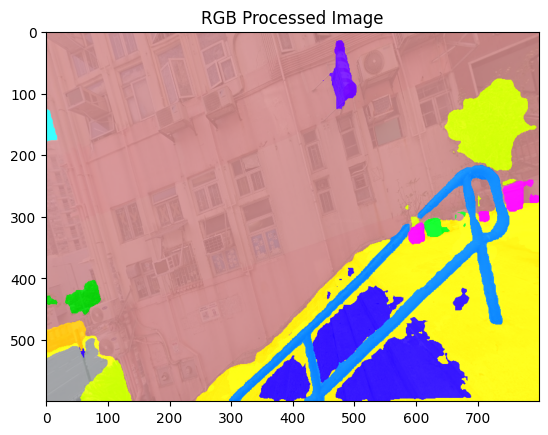

Processed 56/99 images, 82_114.2020049_22.3463252.jpg
Processed 56/99 images, 82_114.2020049_22.3463252.jpg


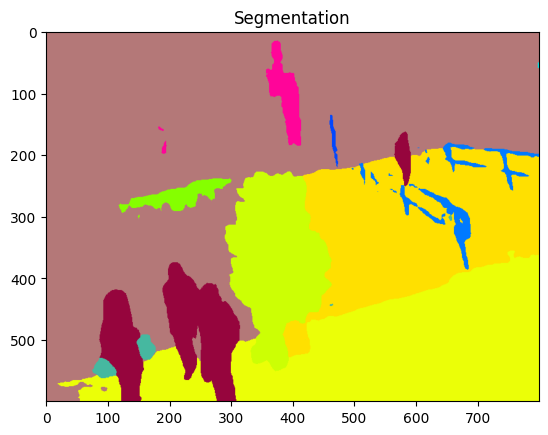

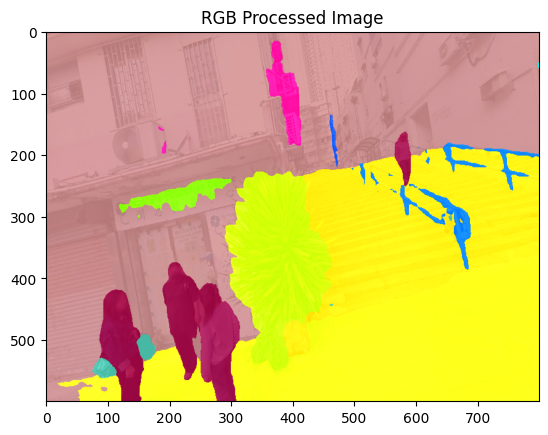

Processed 57/99 images, 86_114.2038365_22.34657859.jpg
Processed 57/99 images, 86_114.2038365_22.34657859.jpg


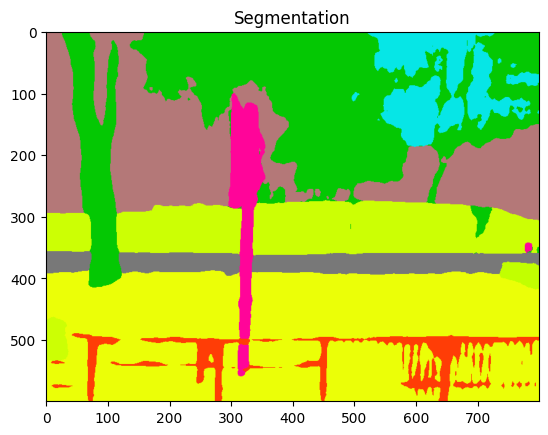

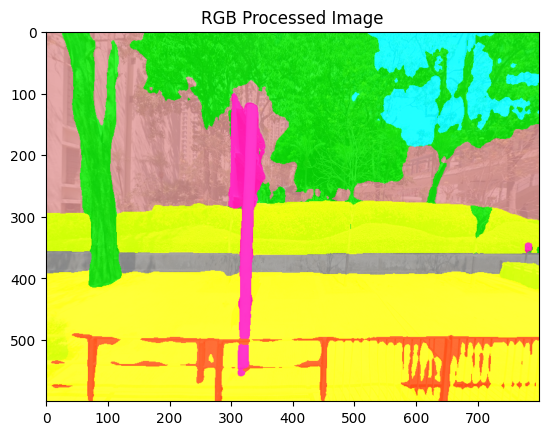

Processed 58/99 images, 84_114.2030357_22.3464677.jpg
Processed 58/99 images, 84_114.2030357_22.3464677.jpg


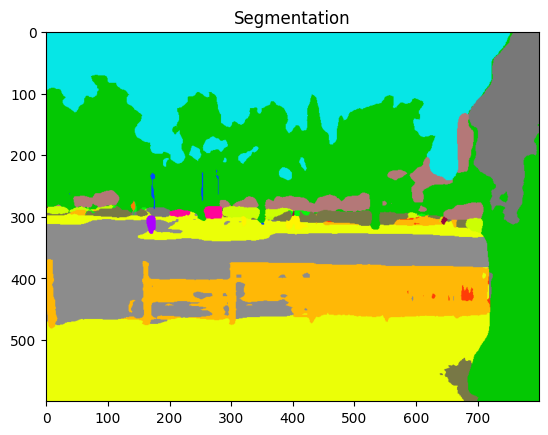

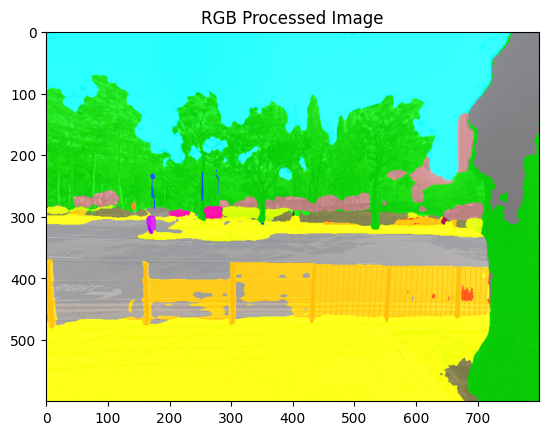

Processed 59/99 images, 110_114.2019277_22.3460917.jpg
Processed 59/99 images, 110_114.2019277_22.3460917.jpg


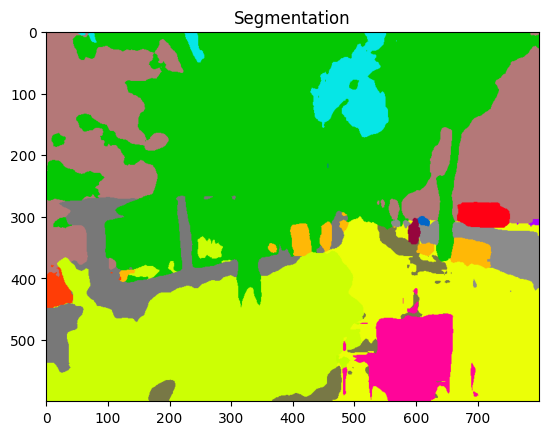

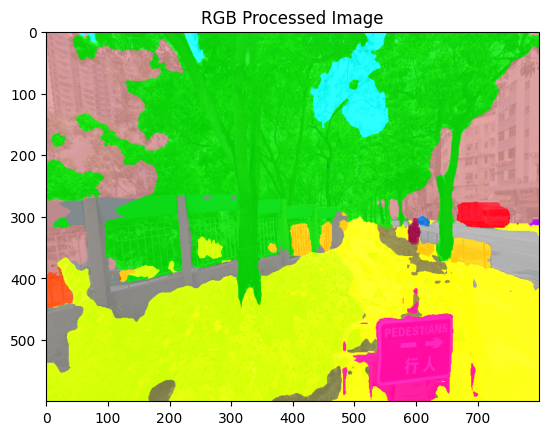

Processed 60/99 images, 11_114.2027903_22.34424276.jpg
Processed 60/99 images, 11_114.2027903_22.34424276.jpg


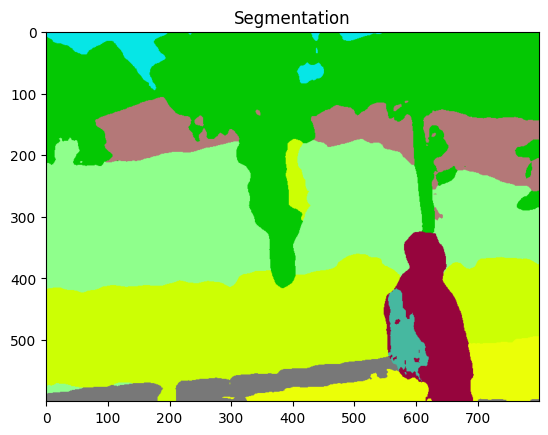

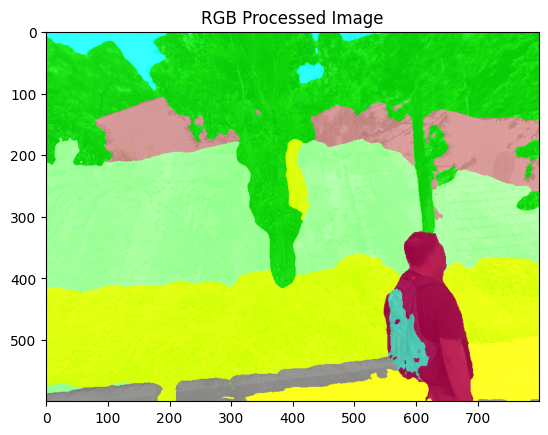

Processed 61/99 images, 29_114.2035459_22.3453913.jpg
Processed 61/99 images, 29_114.2035459_22.3453913.jpg


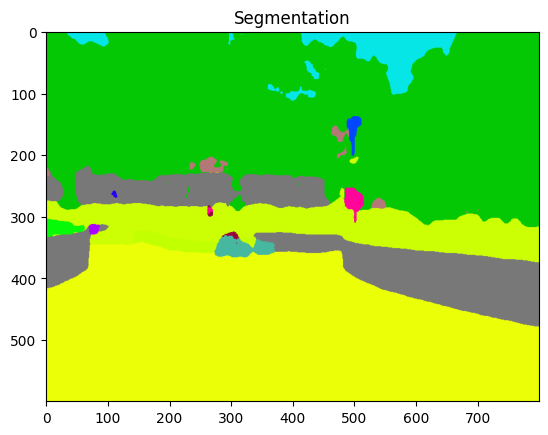

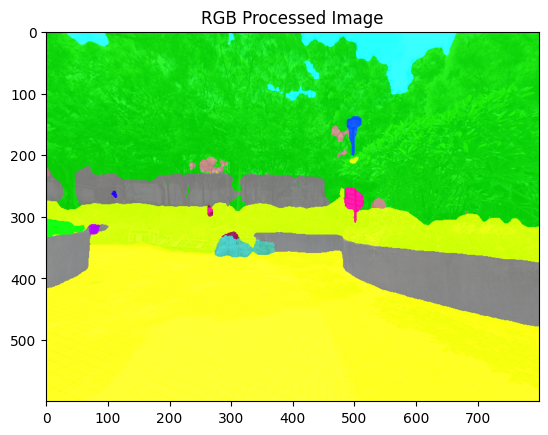

Processed 62/99 images, 3_114.2030226_22.346546.jpg
Processed 62/99 images, 3_114.2030226_22.346546.jpg


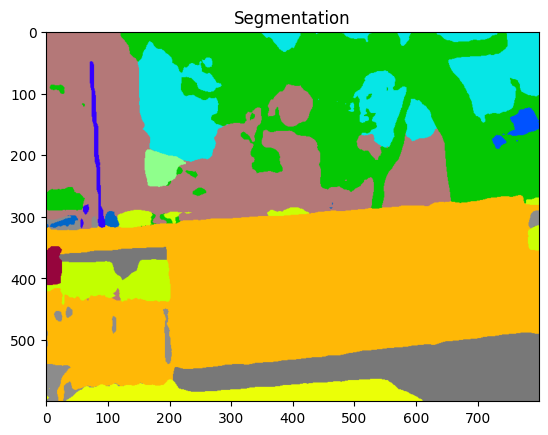

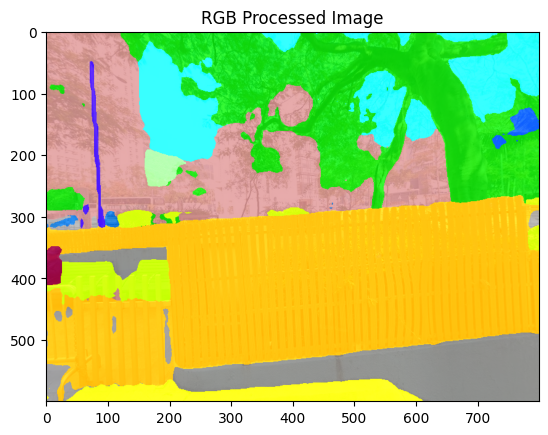

Processed 63/99 images, 100_114.2059183_22.3443658.jpg
Processed 63/99 images, 100_114.2059183_22.3443658.jpg


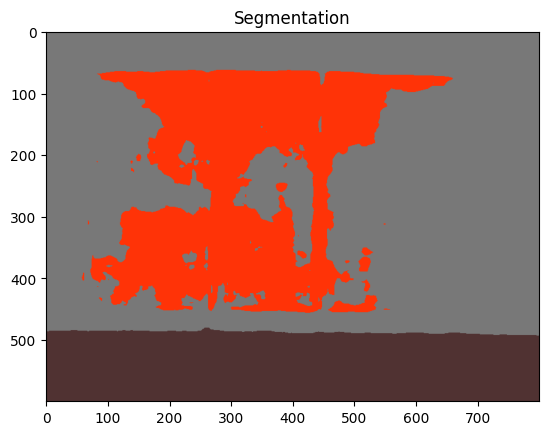

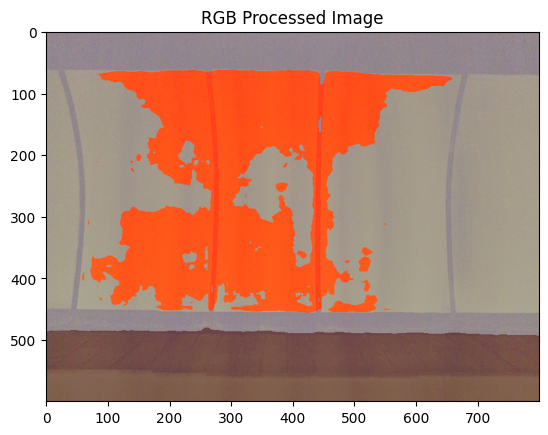

Processed 64/99 images, 85_114.203371_22.3465656.jpg
Processed 64/99 images, 85_114.203371_22.3465656.jpg


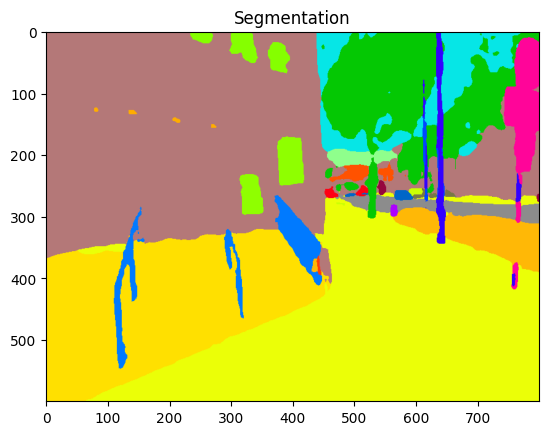

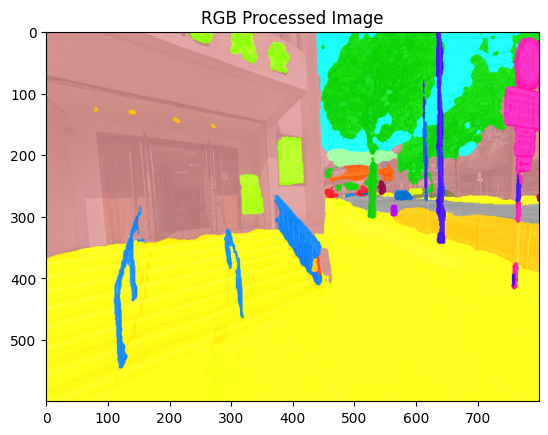

Processed 65/99 images, 80_114.2027035_22.3464205.jpg
Processed 65/99 images, 80_114.2027035_22.3464205.jpg


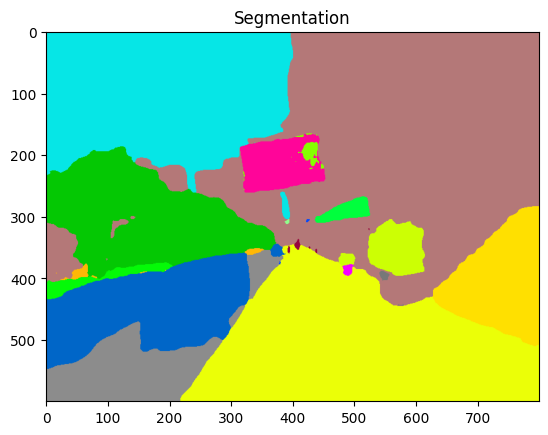

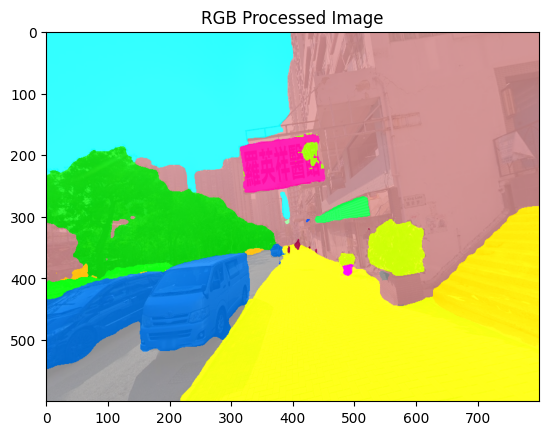

Processed 66/99 images, 1_114.2023406_22.3464788.jpg
Processed 66/99 images, 1_114.2023406_22.3464788.jpg


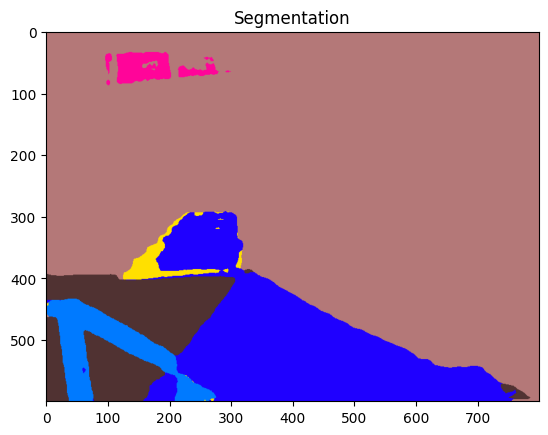

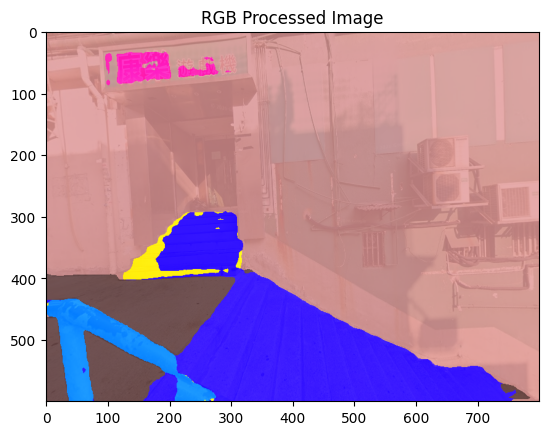

Processed 67/99 images, 6_114.2018435_22.3462117.jpg
Processed 67/99 images, 6_114.2018435_22.3462117.jpg


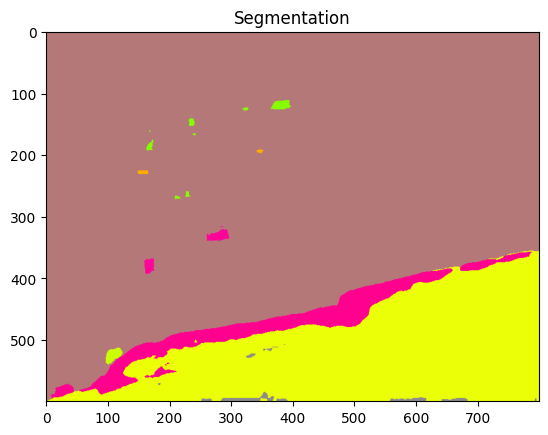

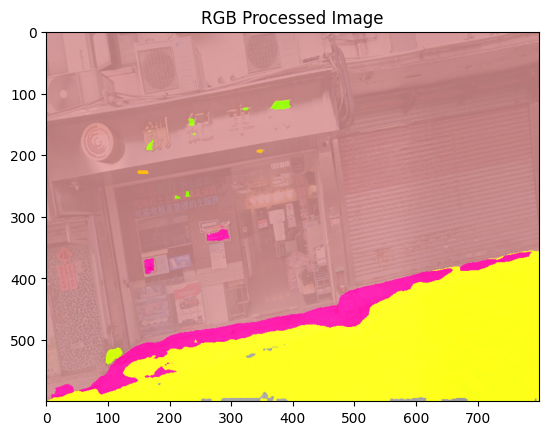

Processed 68/99 images, 69_114.2018236_22.3460803.jpg
Processed 68/99 images, 69_114.2018236_22.3460803.jpg


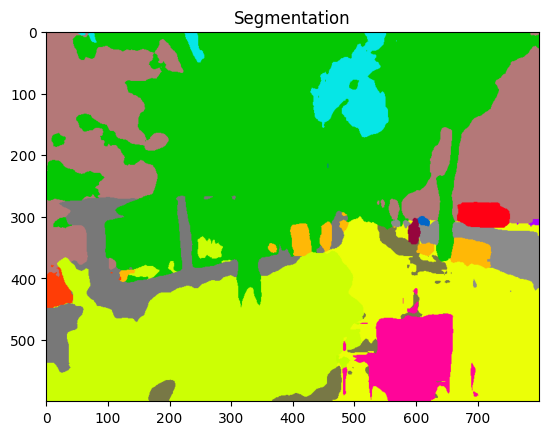

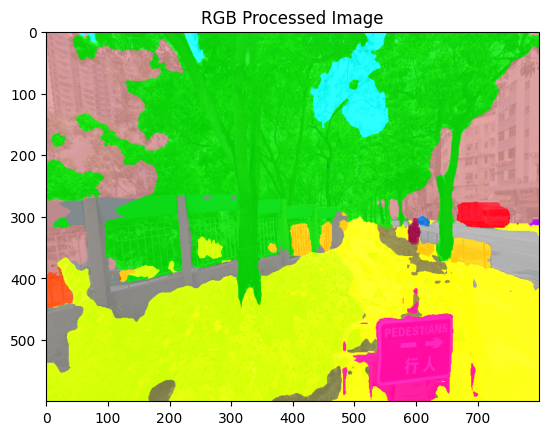

Processed 69/99 images, 61_114.2050493_22.34293033.jpg
Processed 69/99 images, 61_114.2050493_22.34293033.jpg


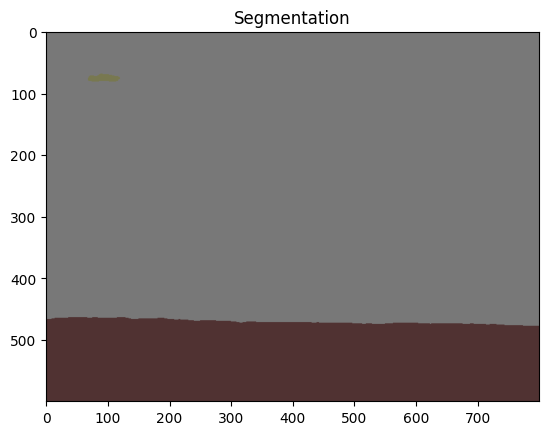

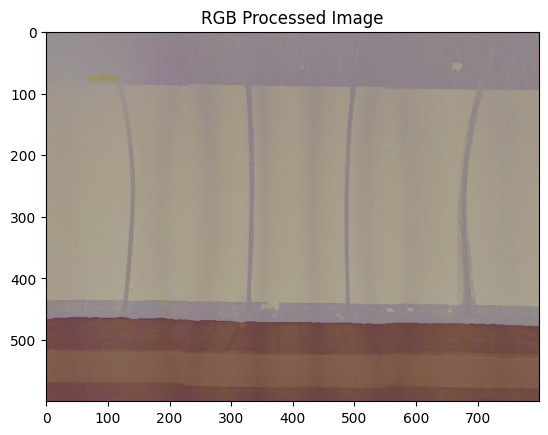

Processed 70/99 images, 112_114.2023813_22.34535835.jpg
Processed 70/99 images, 112_114.2023813_22.34535835.jpg


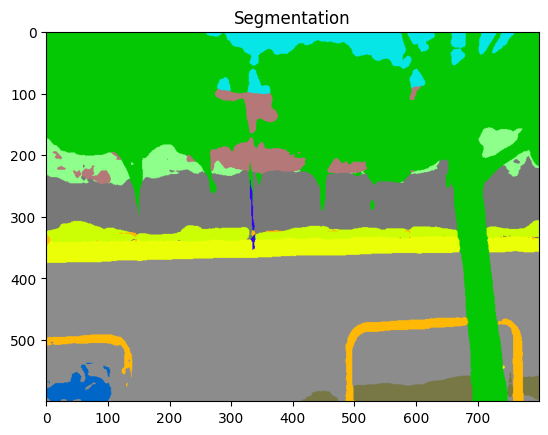

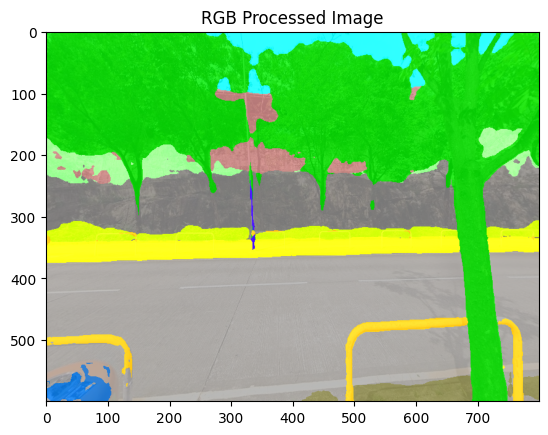

Processed 71/99 images, 93_114.2031277_22.34668196.jpg
Processed 71/99 images, 93_114.2031277_22.34668196.jpg


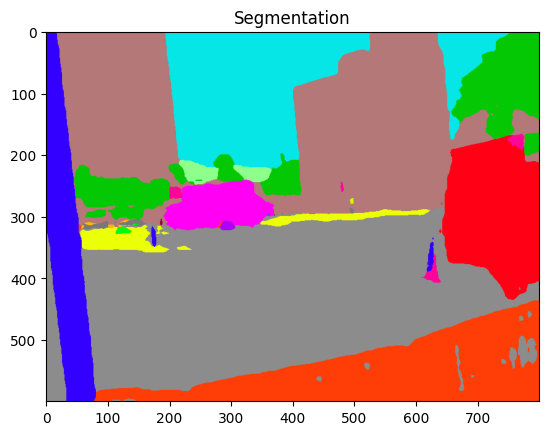

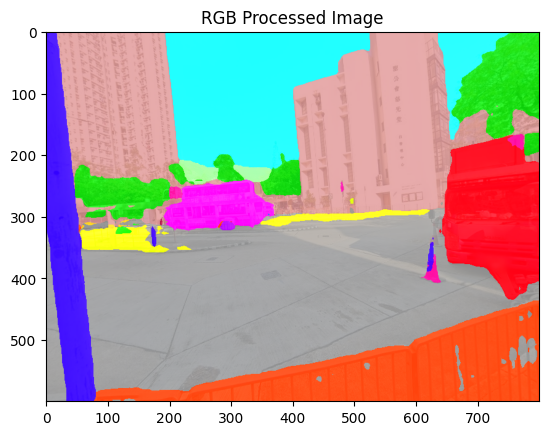

Processed 72/99 images, 18_114.2028367_22.34373814.jpg
Processed 72/99 images, 18_114.2028367_22.34373814.jpg


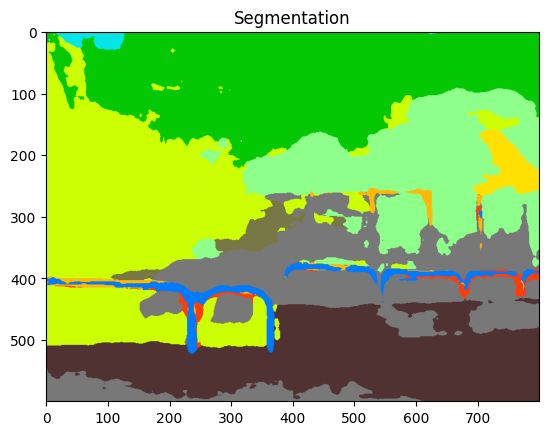

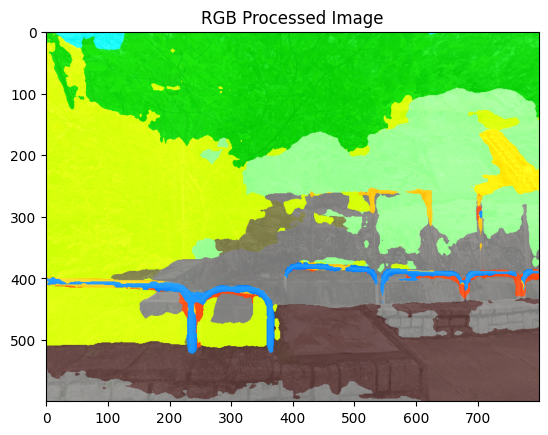

Processed 73/99 images, 21_114.2023233_22.34628031.jpg
Processed 73/99 images, 21_114.2023233_22.34628031.jpg


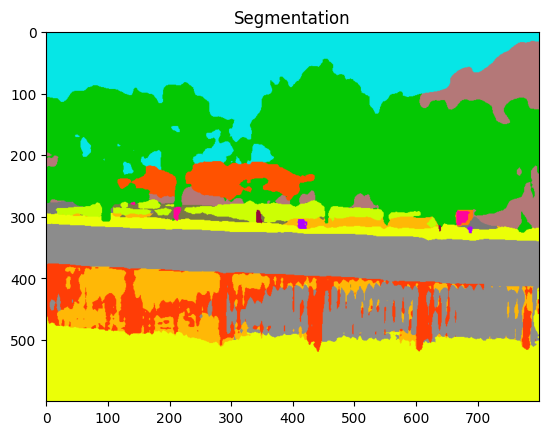

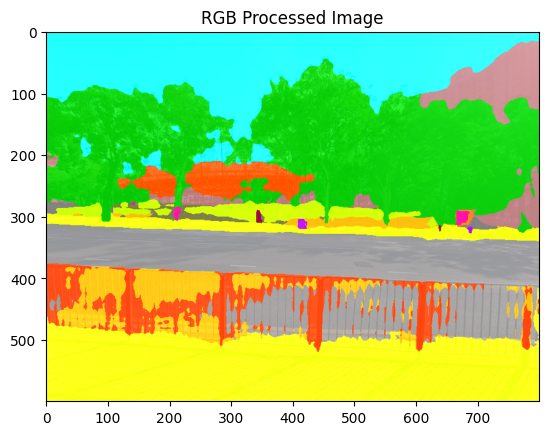

Processed 74/99 images, 36_114.2036726_22.3452791.jpg
Processed 74/99 images, 36_114.2036726_22.3452791.jpg


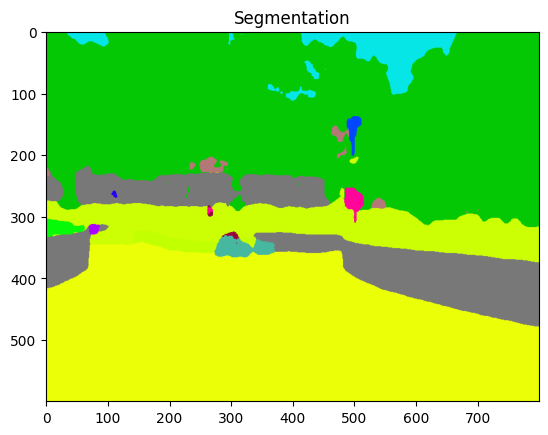

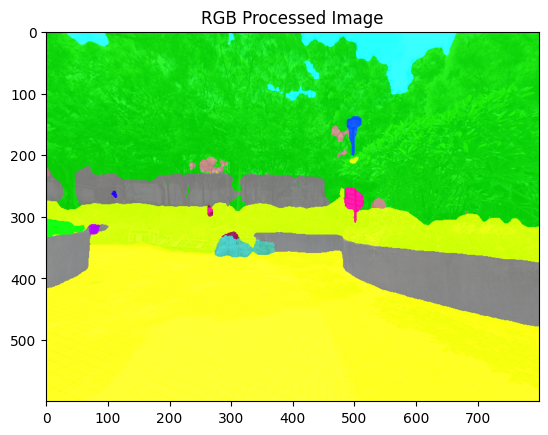

Processed 75/99 images, 7_114.201917_22.34576538.jpg
Processed 75/99 images, 7_114.201917_22.34576538.jpg


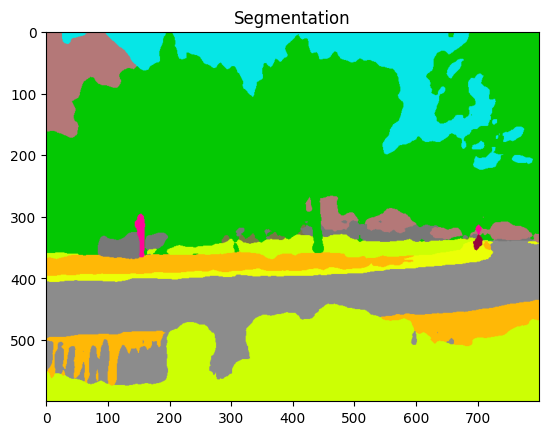

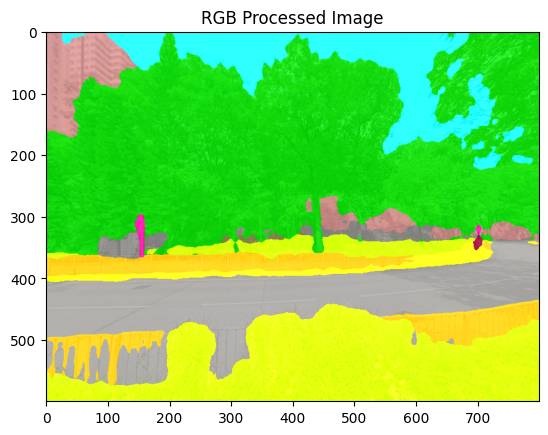

Processed 76/99 images, 76_114.203799_22.34640451.jpg
Processed 76/99 images, 76_114.203799_22.34640451.jpg


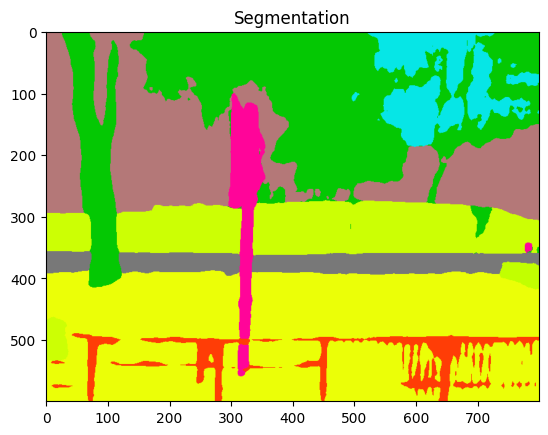

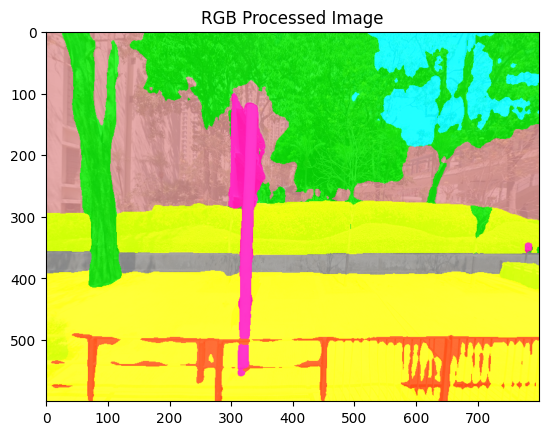

Processed 77/99 images, 74_114.2028394_22.34626785.jpg
Processed 77/99 images, 74_114.2028394_22.34626785.jpg


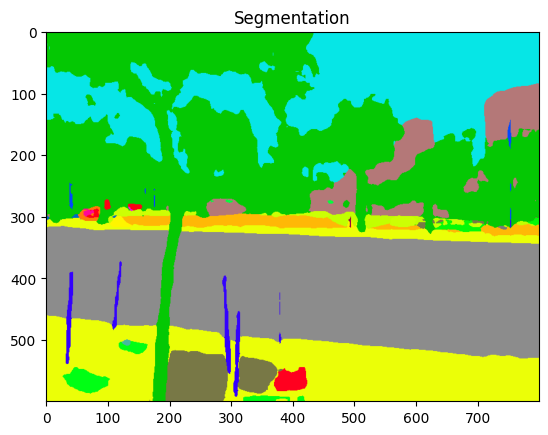

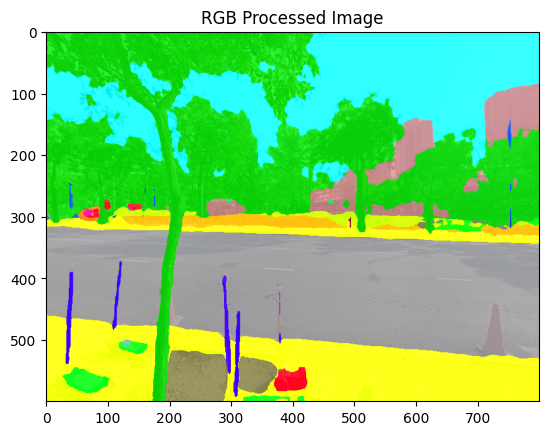

Processed 78/99 images, 13_114.2063507_22.34549906.jpg
Processed 78/99 images, 13_114.2063507_22.34549906.jpg


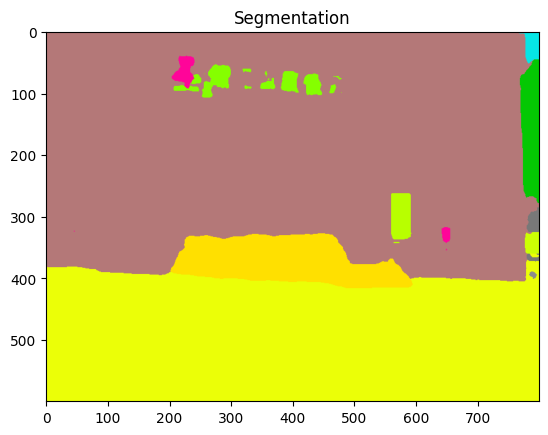

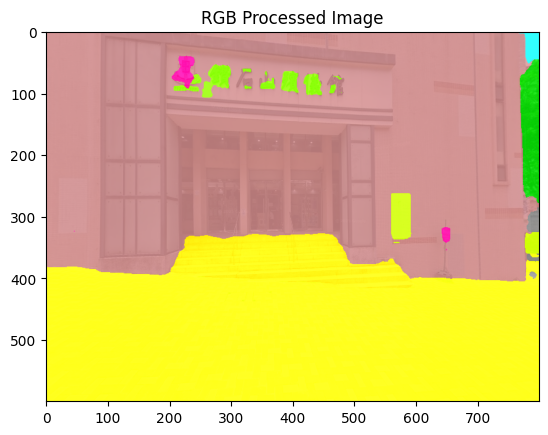

Processed 79/99 images, 87_114.203371_22.3465656.jpg
Processed 79/99 images, 87_114.203371_22.3465656.jpg


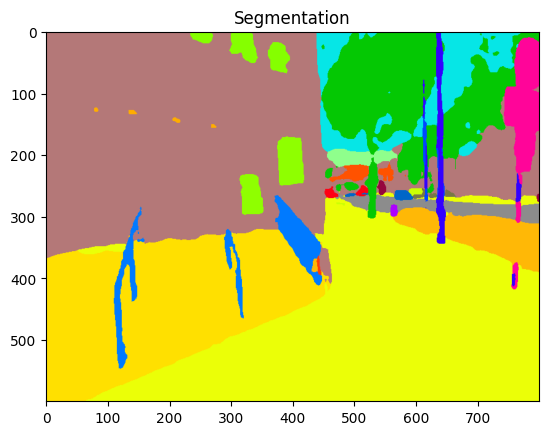

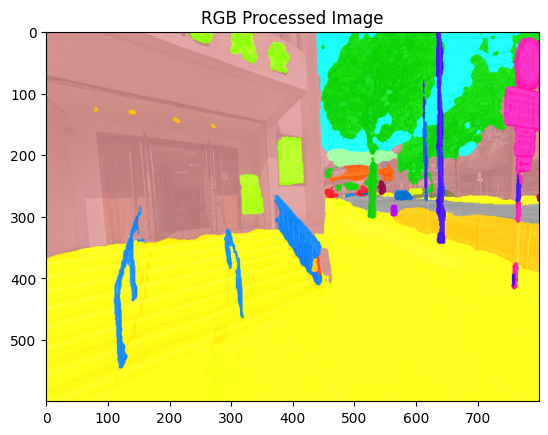

Processed 80/99 images, 5_114.2040321_22.3463627.jpg
Processed 80/99 images, 5_114.2040321_22.3463627.jpg


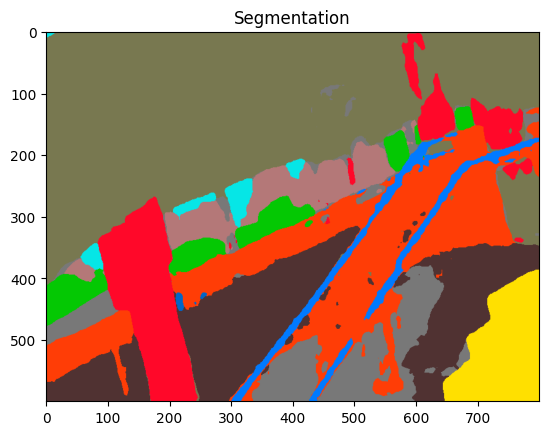

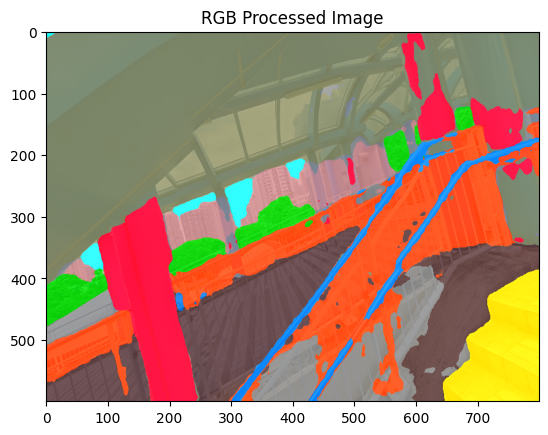

Processed 81/99 images, 31_114.2035119_22.34471523.jpg
Processed 81/99 images, 31_114.2035119_22.34471523.jpg


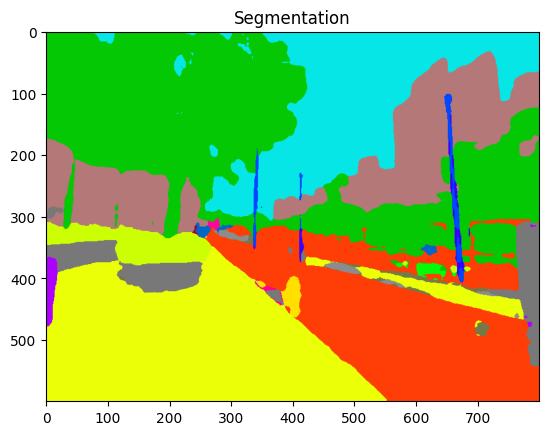

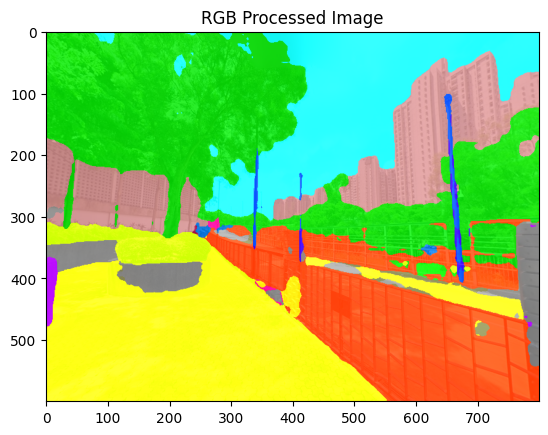

Processed 82/99 images, 2_114.2026851_22.3465367.jpg
Processed 82/99 images, 2_114.2026851_22.3465367.jpg


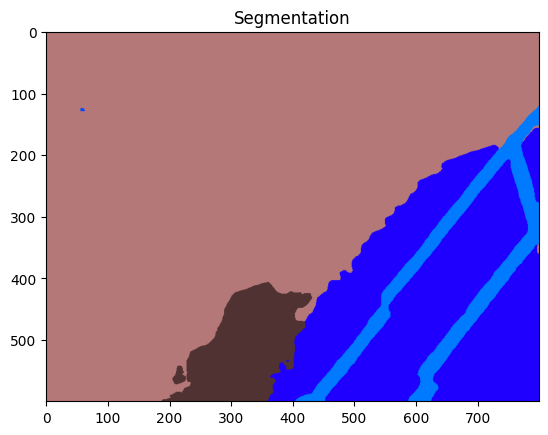

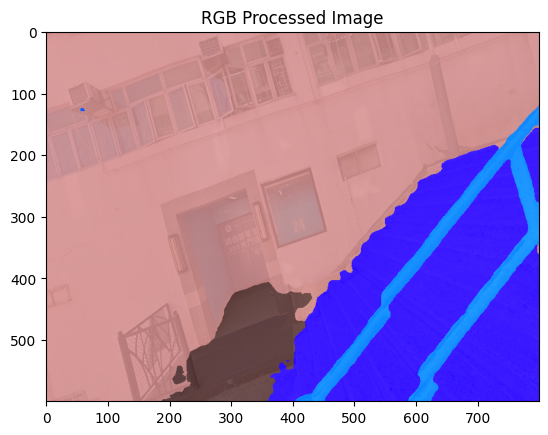

Processed 83/99 images, 67_114.2057579_22.34453148.jpg
Processed 83/99 images, 67_114.2057579_22.34453148.jpg


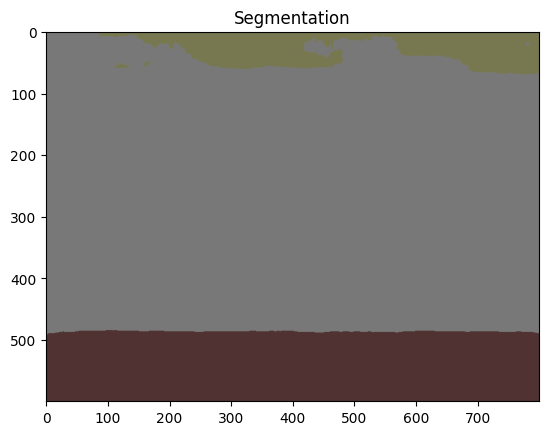

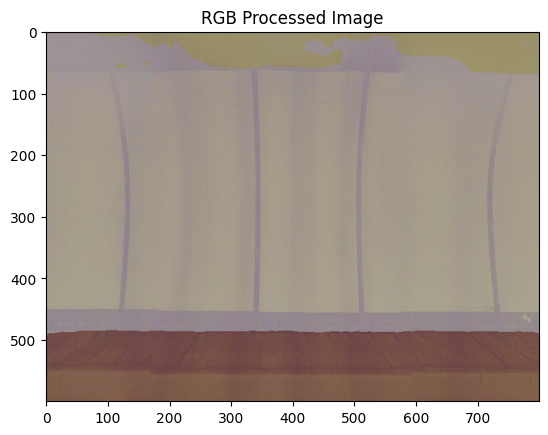

Processed 84/99 images, 9_114.2025565_22.34511758.jpg
Processed 84/99 images, 9_114.2025565_22.34511758.jpg


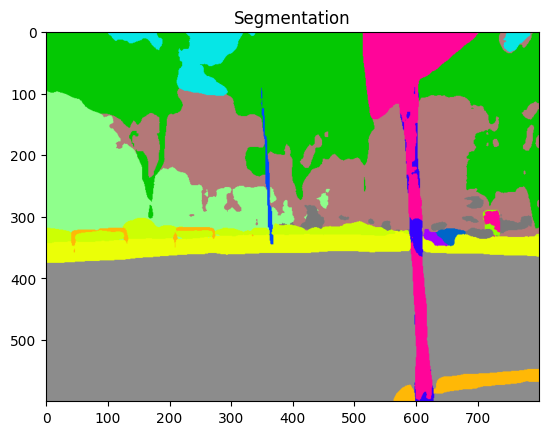

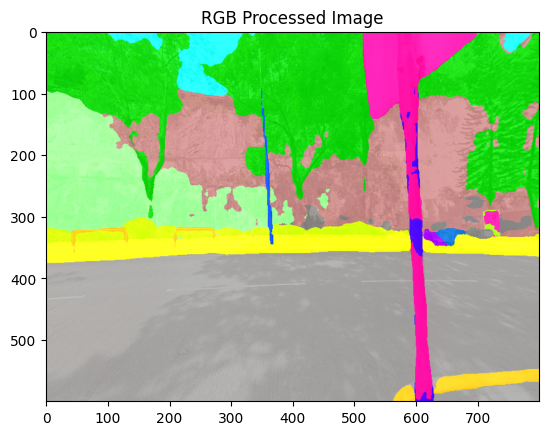

Processed 85/99 images, 114_114.2026618_22.3450007.jpg
Processed 85/99 images, 114_114.2026618_22.3450007.jpg


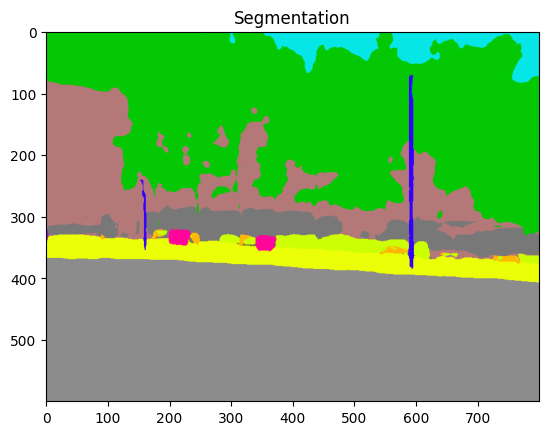

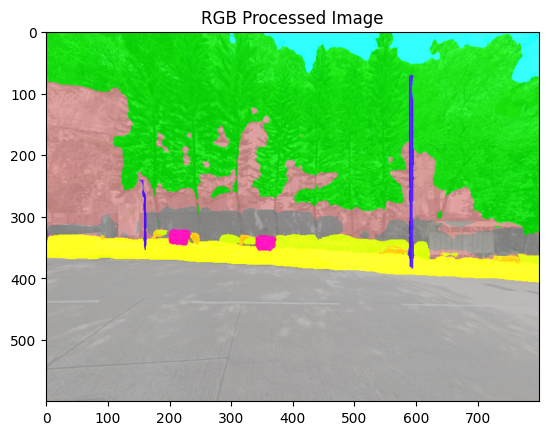

Processed 86/99 images, 68_114.2040281_22.3463752.jpg
Processed 86/99 images, 68_114.2040281_22.3463752.jpg


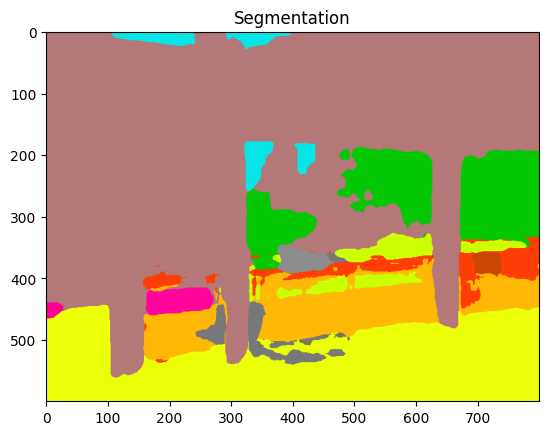

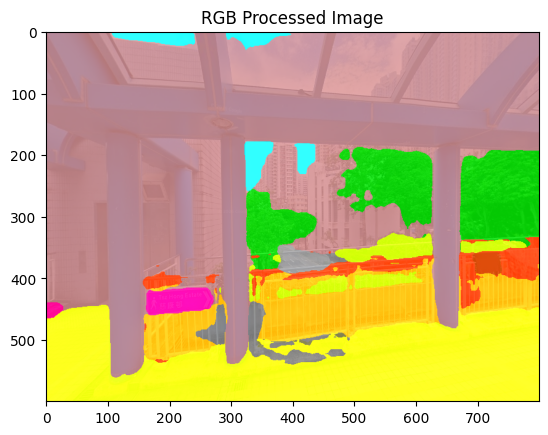

Processed 87/99 images, 22_114.2028037_22.34634484.jpg
Processed 87/99 images, 22_114.2028037_22.34634484.jpg


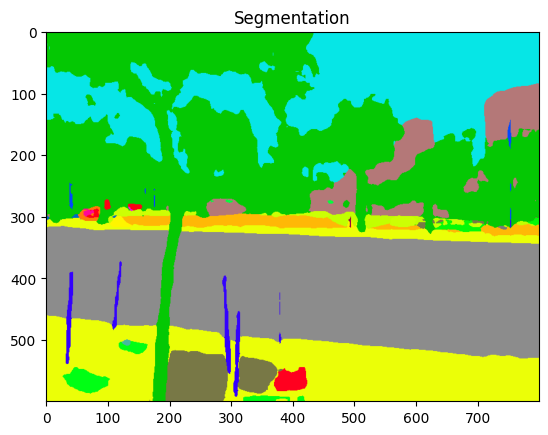

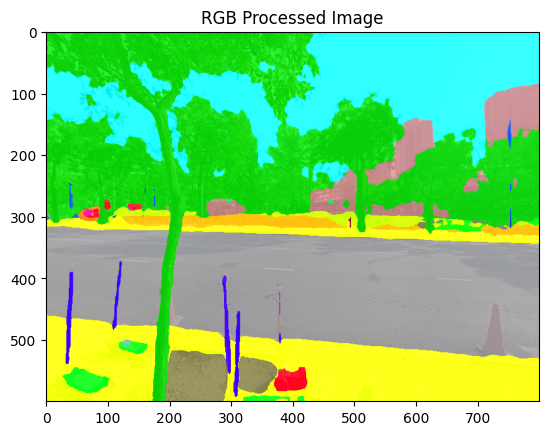

Processed 88/99 images, 97_114.2033557_22.3465709.jpg
Processed 88/99 images, 97_114.2033557_22.3465709.jpg


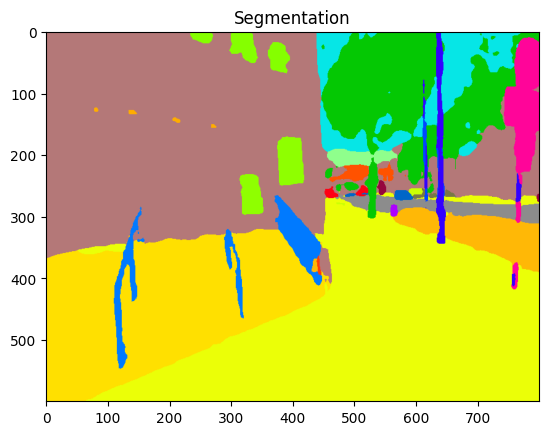

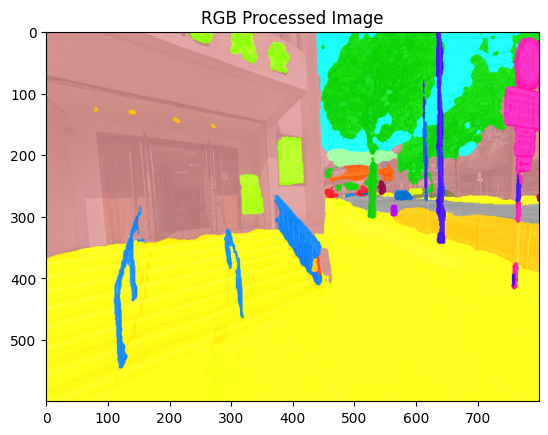

Processed 89/99 images, 107_114.2022712_22.34530258.jpg
Processed 89/99 images, 107_114.2022712_22.34530258.jpg


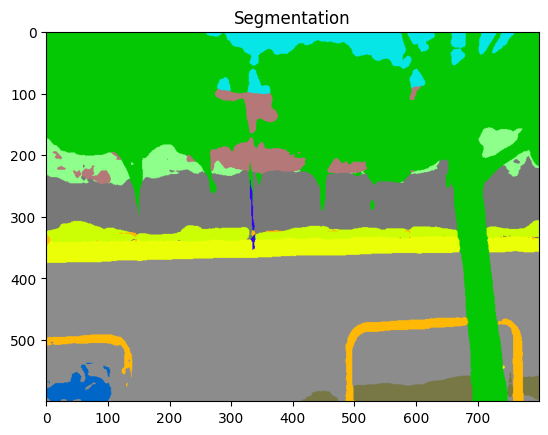

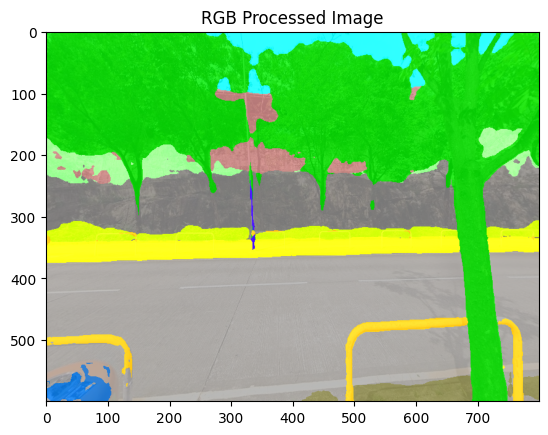

Processed 90/99 images, 98_114.2033317_22.3464175.jpg
Processed 90/99 images, 98_114.2033317_22.3464175.jpg


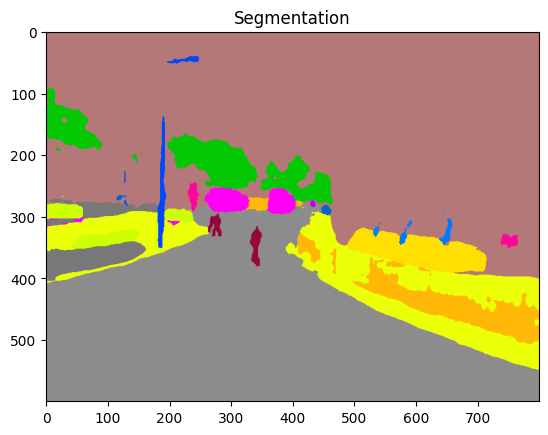

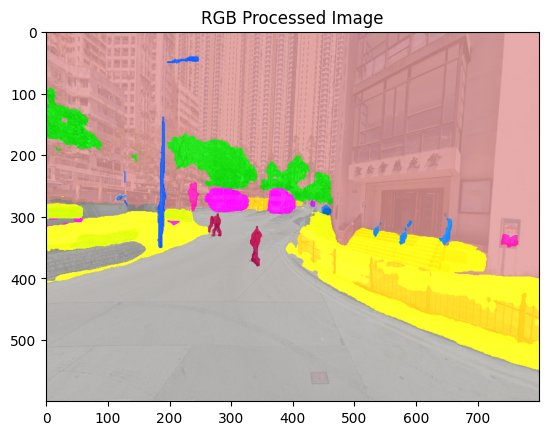

Processed 91/99 images, 104_114.2026444_22.34410271.jpg
Processed 91/99 images, 104_114.2026444_22.34410271.jpg


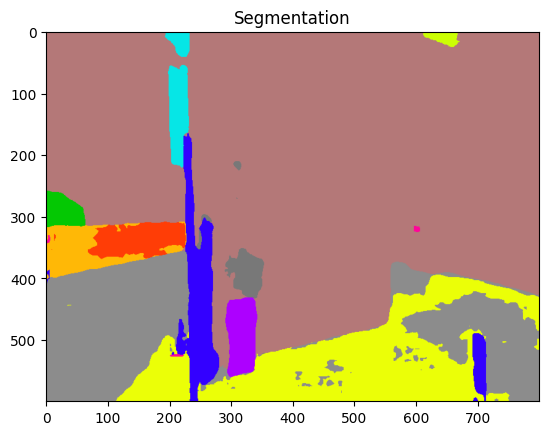

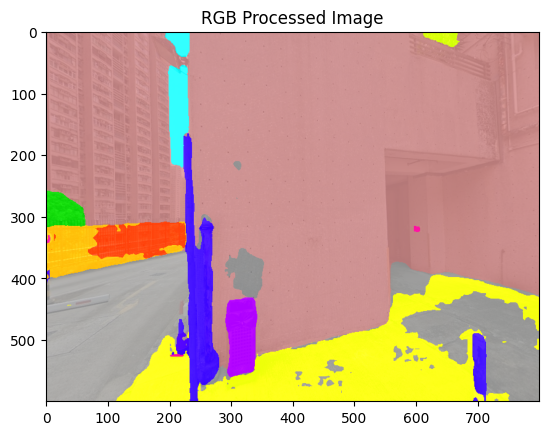

Processed 92/99 images, 33_114.2031975_22.3462351.jpg
Processed 92/99 images, 33_114.2031975_22.3462351.jpg


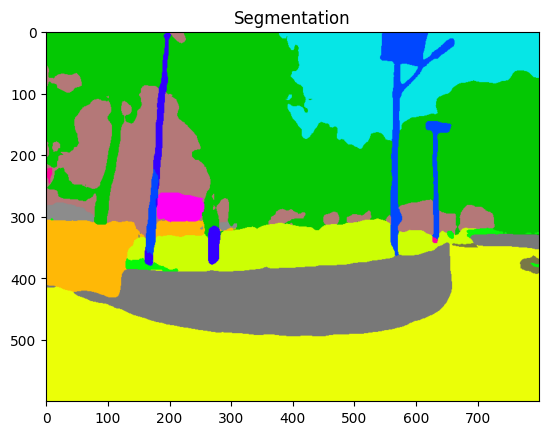

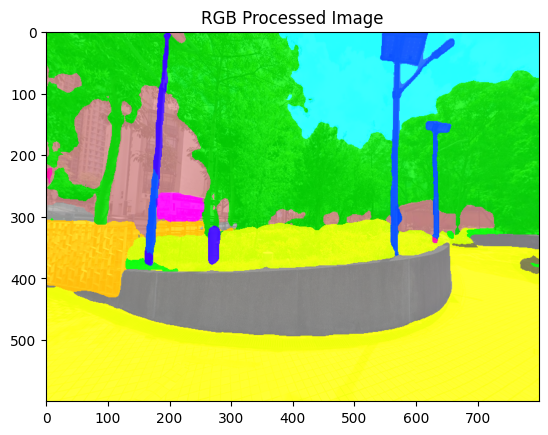

Processed 93/99 images, 45_114.2064799_22.34548589.jpg
Processed 93/99 images, 45_114.2064799_22.34548589.jpg


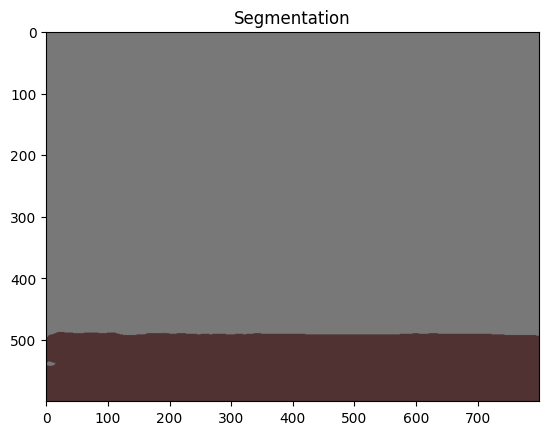

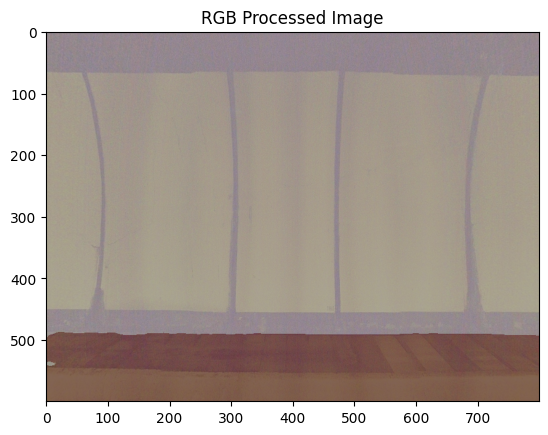

Processed 94/99 images, 30_114.2033501_22.34513943.jpg
Processed 94/99 images, 30_114.2033501_22.34513943.jpg


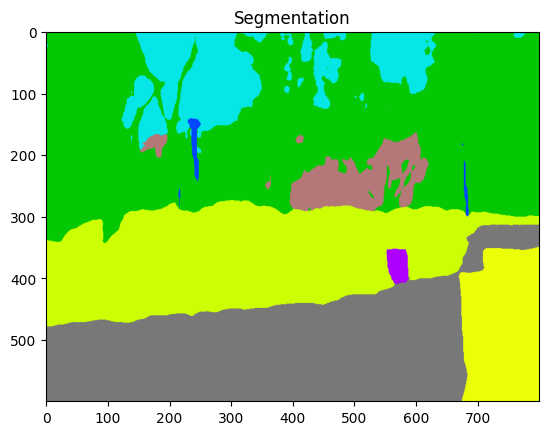

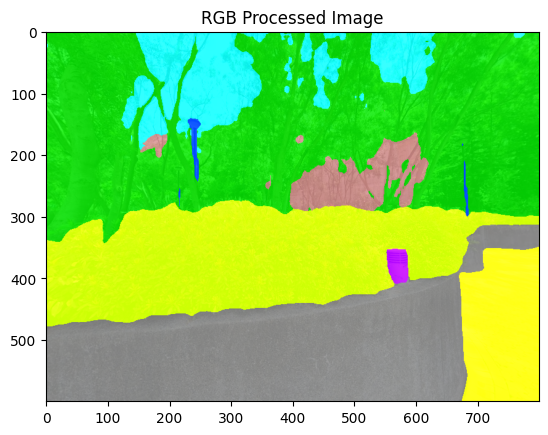

Processed 95/99 images, 101_114.2026618_22.3450007.jpg
Processed 95/99 images, 101_114.2026618_22.3450007.jpg


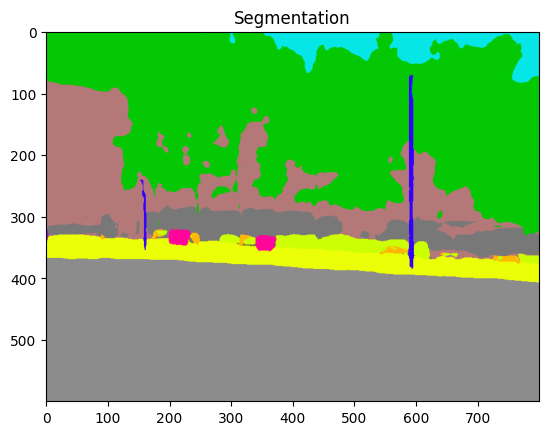

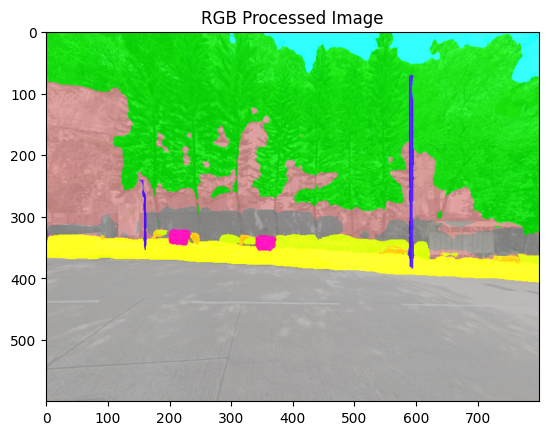

Processed 96/99 images, 109_114.2019048_22.34563794.jpg
Processed 96/99 images, 109_114.2019048_22.34563794.jpg


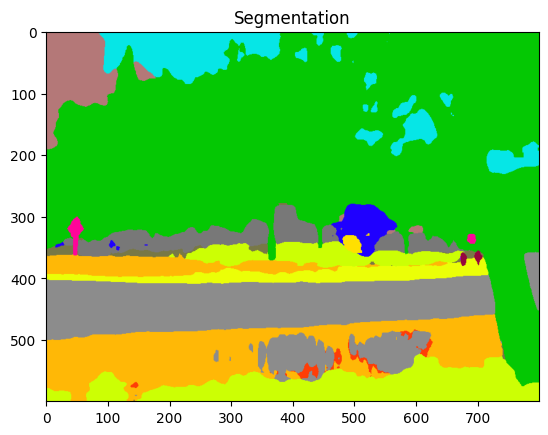

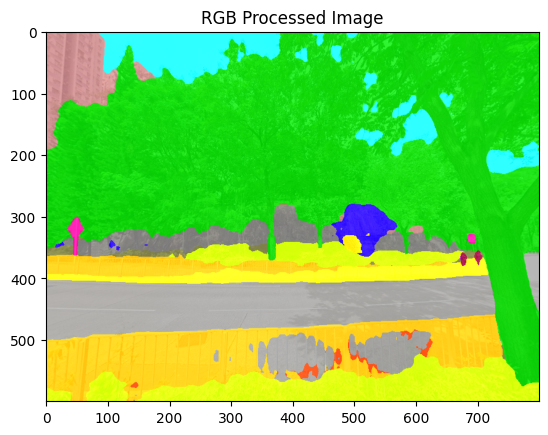

Processed 97/99 images, 77_114.2031975_22.3462351.jpg
Processed 97/99 images, 77_114.2031975_22.3462351.jpg


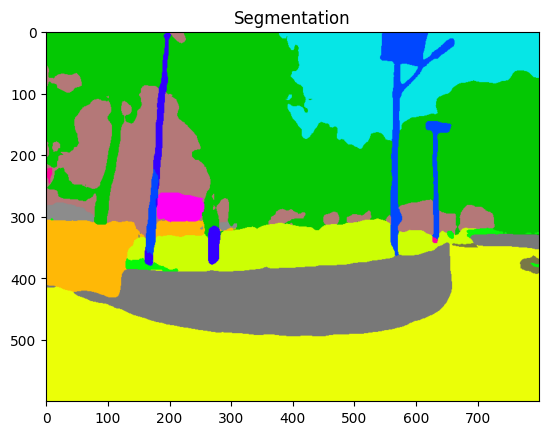

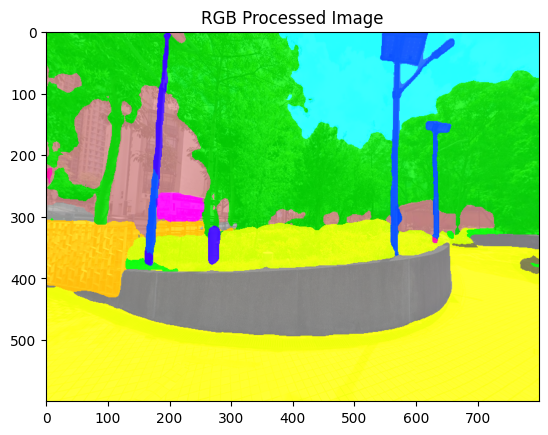

Processed 98/99 images, 83_114.2023569_22.3463726.jpg
Processed 98/99 images, 83_114.2023569_22.3463726.jpg


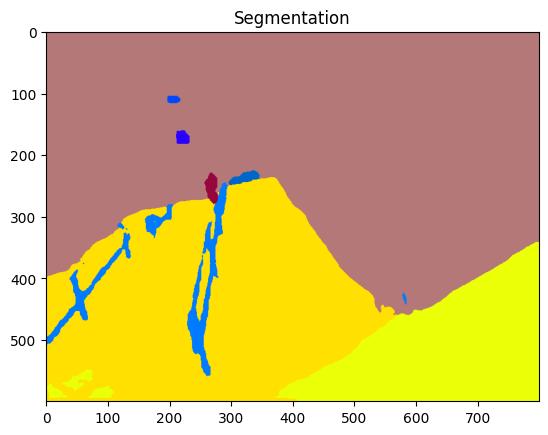

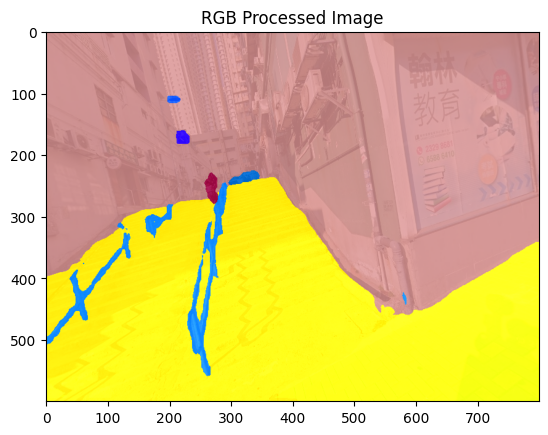

Processed 99/99 images, 95_114.2030617_22.3464714.jpg
Processed 99/99 images, 95_114.2030617_22.3464714.jpg


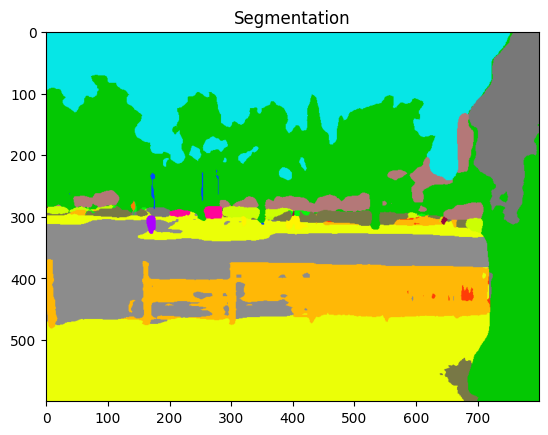

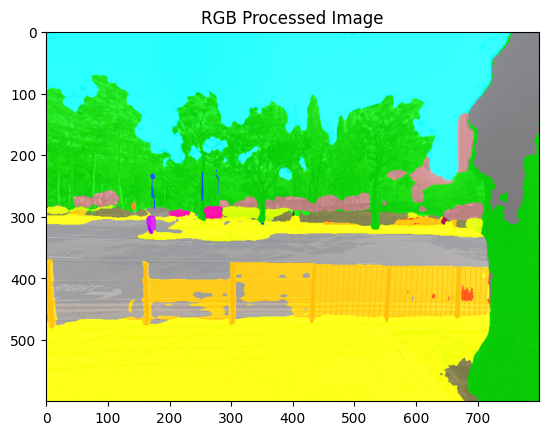

In [ ]:
# @title ▶️ step 3 locate to your local model path and process image！！！
from transformers import AutoFeatureExtractor, MaskFormerForInstanceSegmentation
from transformers import MaskFormerImageProcessor
import torch

# Specify the path to your local model directory
local_model_path = "maskformer_offline"   # @param {type:"string"} # your model folder name
out_dir = "/content/drive/MyDrive/SVI/GPan/svi_seg31"  # @param {type:"string"} # your model folder name
# Load the feature extractor and model
#processor = AutoFeatureExtractor.from_pretrained(local_model_path)
processor = MaskFormerImageProcessor.from_pretrained(local_model_path)

model = MaskFormerForInstanceSegmentation.from_pretrained(local_model_path)

# Move the model to the appropriate device (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)


# Process each image
for filename in os.listdir(args.input_dir):
    if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
        current_image += 1  # Increment the counter
        image_path = os.path.join(args.input_dir, filename)
        image = Image.open(image_path).convert('RGB')
        inputs = processor(image, return_tensors='pt').to(device)

        with torch.no_grad():
            outputs = model(**inputs)

        pred_map = processor.post_process_semantic_segmentation(outputs, target_sizes=[image.size[::-1]])[0]
        mask = pred_map.cpu().numpy()  # Get the mask as a numpy array
        categories = ADE_CATEGORIES
        # Draw segmentation map
        seg_map = draw_segmentation_map(mask, ADE_CATEGORIES)
        # Overlay the segmentation map on the original image
        #overlay_image = image_overlay(np.array(image), segmentation_map)
        result = image_overlay(image, seg_map)  # Overlay on the original image
        result_o = seg_map
        # Convert result from BGR to RGB
        result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

        # Convert the result back to PIL image to save
        result_pil = Image.fromarray(result)
        save_name = filename
        result_pil.save(os.path.join(out_dir, save_name))
        print(f"Processed {current_image}/{total_images} images, {filename}")

        # Convert the result back to PIL image to save
        result_pil_o = Image.fromarray(result_o)
        save_name = filename
        result_pil_o.save(os.path.join(out_dir, save_name))
        print(f"Processed {current_image}/{total_images} images, {filename}")

        # # Display the image in Jupyter
        # plt.imshow(result_rgb)
        # plt.show()

        # Display the result image (segmentation map overlayed on original image)
        plt.imshow(result_o)  # 显示seg_map
        plt.title('Segmentation')  # 可选，显示标题
        plt.show()  # 显示图像

        # Display the result_rgb image (RGB image after BGR to RGB conversion)
        plt.imshow(result_rgb)  # 显示处理后的图像
        plt.title('RGB Processed Image')  # 可选，显示标题
        plt.show()  # 显示图像



        # Calculate the area ratio for each category
        total_pixels = mask.size
        label_ratios = {'Category_' + str(index): np.sum(mask == index) / total_pixels for index in range(len(categories))}
        label_ratios['ImageName'] = filename

        # Create a DataFrame for the current image data
        current_df = pd.DataFrame([label_ratios])

        # Concatenate the new row to the main DataFrame
        df = pd.concat([df, current_df], ignore_index=True)
                # Overlay the segmentation map on the original image


In [ ]:
# @title ▶️ step 3.2 save your segmentation result csv ！！！

# Load the label of ADE20K
label = pd.read_csv('ade20k_label.csv')

label
# Create dictionary
rename_dict = dict(zip(label['Columnname'], label['Name']))

# Rename the columns in csv1 based on the mapping
df.rename(columns=rename_dict, inplace=True)


# Save segmentation results to CSV
df.to_csv('/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former72right.csv', index=False)

df

,ImageName,wall,building,sky,floor,tree,ceiling,road,bed,windowpane,...,pier,crt,plate,monitor,bulletin,shower,radiator,glass,clock,flag
0,106_114.2025579_22.34495589.jpg,0.049658,0.134090,0.030558,0.000000,0.348752,0.000000,0.359767,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,41_114.206538_22.34513935.jpg,0.072210,0.185642,0.039988,0.000000,0.204910,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,99_114.2038118_22.34648376.jpg,0.046627,0.182537,0.053079,0.000000,0.234763,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,15_114.2069954_22.34482391.jpg,0.022598,0.071031,0.000000,0.262321,0.006292,0.178475,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,108_114.2018056_22.3460782.jpg,0.052690,0.151615,0.027056,0.000000,0.379490,0.000000,0.018071,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,101_114.2026618_22.3450007.jpg,0.049658,0.134090,0.030558,0.000000,0.348752,0.000000,0.359767,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
95,109_114.2019048_22.34563794.jpg,0.033477,0.029481,0.051715,0.000000,0.488910,0.000000,0.142025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
96,77_114.2031975_22.3462351.jpg,0.120858,0.083852,0.093025,0.000000,0.311723,0.000000,0.004354,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
97,83_114.2023569_22.3463726.jpg,0.000000,0.572892,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
import re
import pandas as pd # Import pandas to ensure pd.read_csv is available

# Load the df DataFrame from the CSV file where it was last saved in step 3.2
df = pd.read_csv('/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former72right.csv')

def extract_lat_lon(image_name):
    # The pattern expects a format like 'ID_longitude_latitude.jpg'
    # Example: '1_9.1683589_45.4760388.jpg'
    # The regex extracts the two float numbers separated by an underscore, preceded by an ID and underscore, and followed by .jpg.
    match = re.search(r'\d+_([-+]?\d+\.\d+)_([-+]?\d+\.\d+)\.jpg', image_name)
    if match:
        longitude = float(match.group(1))
        latitude = float(match.group(2))
        return longitude, latitude
    return None, None

# Apply the function to the 'ImageName' column
df[['Lng', 'Lat']] = df['ImageName'].apply(lambda x: pd.Series(extract_lat_lon(x)))

print("First 5 rows of the DataFrame with new Latitude and Longitude columns:")
print(df.head())

# Create a new DataFrame with only the requested 'ImageName', 'Latitude', and 'Longitude' columns
coordinates_df = df[['ImageName', 'Lat', 'Lng']].copy()

# Define the output path for the new CSV file
output_path = '/content/drive/MyDrive/SVI/SVI_seg2/ImageCoordinates72right.csv'

# Save the new DataFrame to a CSV file
coordinates_df.to_csv(output_path, index=False)
print(f"\nCoordinates (ImageName, Latitude, Longitude) saved to: {output_path}")

First 5 rows of the DataFrame with new Latitude and Longitude columns:
                         ImageName      wall  building       sky     floor  \
0  106_114.2025579_22.34495589.jpg  0.049658  0.134090  0.030558  0.000000   
1    41_114.206538_22.34513935.jpg  0.072210  0.185642  0.039988  0.000000   
2   99_114.2038118_22.34648376.jpg  0.046627  0.182537  0.053079  0.000000   
3   15_114.2069954_22.34482391.jpg  0.022598  0.071031  0.000000  0.262321   
4   108_114.2018056_22.3460782.jpg  0.052690  0.151615  0.027056  0.000000   

       tree   ceiling      road  bed  windowpane  ...  plate  monitor  \
0  0.348752  0.000000  0.359767  0.0         0.0  ...    0.0      0.0   
1  0.204910  0.000000  0.000000  0.0         0.0  ...    0.0      0.0   
2  0.234763  0.000000  0.000000  0.0         0.0  ...    0.0      0.0   
3  0.006292  0.178475  0.000000  0.0         0.0  ...    0.0      0.0   
4  0.379490  0.000000  0.018071  0.0         0.0  ...    0.0      0.0   

   bulletin  shower  

In [ ]:
import pandas as pd

# 1. 定义你的四个文件路径
file_paths = [
    '/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former72front.csv',
    '/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former72left.csv',
    '/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former72rear.csv',
    '/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former72right.csv'
]

# 2. 定义哪些列属于“植被” (根据你提供的列名筛选)
# 你可以根据需要增加或减少这些类别
vegetation_columns = ['tree', 'grass', 'plant', 'flower', 'palm']

all_gvi_values = []

# 3. 计算每个文件的平均 GVI
for path in file_paths:
    try:
        df = pd.read_csv(path)

        # 筛选存在的植被列，防止报错
        existing_veg_cols = [col for col in vegetation_columns if col in df.columns]

        # 计算每一行（每一张图）的植被占比总和
        df['total_veg'] = df[existing_veg_cols].sum(axis=1)

        # 将该文件所有图片的植被占比取平均值
        avg_gvi = df['total_veg'].mean()
        all_gvi_values.append(avg_gvi)

        print(f"文件 {path.split('/')[-1]} 的平均植被占比: {avg_gvi:.4f}")

    except Exception as e:
        print(f"处理文件 {path} 时出错: {e}")

# 4. 计算四个视角的总 GVI (取四个视角的平均值)
if all_gvi_values:
    final_gvi = sum(all_gvi_values) / len(all_gvi_values)
    print("-" * 30)
    print(f"最终 GVI (四个视角的平均值): {final_gvi:.4f} (或 {final_gvi*100:.2f}%)")
else:
    print("未能计算 GVI，请检查文件路径和列名。")

文件 Segmentation_Mask2Former72front.csv 的平均植被占比: 0.1750
文件 Segmentation_Mask2Former72left.csv 的平均植被占比: 0.1492
文件 Segmentation_Mask2Former72rear.csv 的平均植被占比: 0.1715
文件 Segmentation_Mask2Former72right.csv 的平均植被占比: 0.2288
------------------------------
最终 GVI (四个视角的平均值): 0.1811 (或 18.11%)


## Summary:

### Q&A
Yes, the coordinates have been successfully extracted and saved to a new DataFrame in Google Drive. A new CSV file named `ImageCoordinates.csv` containing 'ImageName', 'Latitude', and 'Longitude' was created and saved to the specified path `/content/drive/MyDrive/SVI/SVI_seg/ImageCoordinates.csv`.

### Data Analysis Key Findings
*   Latitude and longitude coordinates were successfully extracted from the 'ImageName' column of the input DataFrame using a regular expression `r'\d+_([-+]?\d+\.\d+),([-+]?\d+\.\d+)_'`.
*   Two new columns, 'Longitude' and 'Latitude', were added to the original DataFrame `df`, containing the extracted numeric coordinates.
*   A new DataFrame, `coordinates_df`, was created, comprising only the 'ImageName', 'Latitude', and 'Longitude' columns.
*   The `coordinates_df` was successfully saved as a CSV file to `/content/drive/MyDrive/SVI/SVI_seg/ImageCoordinates.csv`.

### Insights or Next Steps
*   The extracted coordinate data is now available for geospatial analysis or integration with other location-based datasets.
*   Verify the integrity and correctness of the saved `ImageCoordinates.csv` by loading a sample and spot-checking against the original image names.


In [ ]:
# @title ▶️ step 3.3 case 2 if we merge with the csv locations(not recommend)； merge the result with Lng and Lat with your previous csv (has the SVI_ID and Lat&Lng) ！！！
import pandas as pd
import re

# -------------------------- INPUT PARAMETERS (INTERACTIVE) --------------------------
# Load input CSV files (original paths with interactive support)
segmentation_df_path = "'/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former2.csv'" # @param {type:"string"}
svi_df_path = '/content/drive/MyDrive/SVI/sfsvi.csv' # @param {type:"string"}

# Column names from the coordinate CSV (svi_df) - EDIT THESE TO MATCH YOUR CSV!
svi_id_column = 'SVI_ID' # @param {type:"string"} # Column name for ID in coordinate CSV (used for merging)
latitude_column = 'Lat' # @param {type:"string"} # Column name for Latitude in coordinate CSV
longitude_column = 'Lng' # @param {type:"string"} # Column name for Longitude in coordinate CSV

# Output path (interactive) - where the merged CSV will be saved
output_merged_path = '/content/drive/MyDrive/SVI/Segmentation_Mask2Former_Merged1.csv' # @param {type:"string"}
# -------------------------------------------------------------------------------------

# Load the CSV files
segmentation_df = pd.read_csv(segmentation_df_path)
svi_df = pd.read_csv(svi_df_path)

# Function to extract numeric ID from ImageName (before '.' symbol)
def extract_numeric_id(image_name):
    match = re.match(r'(\d+)', str(image_name))
    return int(match.group(1)) if match else None

# Apply the extraction function to create a new column 'ID' in segmentation_df
segmentation_df['ID'] = segmentation_df['ImageName'].apply(lambda x: extract_numeric_id(str(x).split('.')[0]))

# Ensure the SVI_ID column (from your input) is of integer type for matching
svi_df[svi_id_column] = svi_df[svi_id_column].astype(int)

# Merge the two DataFrames using the interactive column names
# Only select the ID, Latitude, and Longitude columns from svi_df to avoid extra columns
merge_columns = [svi_id_column, latitude_column, longitude_column]
merged_df = pd.merge(
    segmentation_df,
    svi_df[merge_columns],
    left_on='ID',
    right_on=svi_id_column,
    how='left'
)

# Drop the temporary ID columns (extracted ID and SVI_ID from coordinate CSV)
merged_df.drop(columns=['ID', svi_id_column], inplace=True)

# Save the merged result to the interactive output path
merged_df.to_csv(output_merged_path, index=False)

print(f"✅ Merging complete! The merged file is saved to: {output_merged_path}")

FileNotFoundError: [Errno 2] No such file or directory: "'/content/drive/MyDrive/SVI/SVI_seg2/Segmentation_Mask2Former2.csv'"